# Семинар 10. i2i-списки: релевантность и аттрактивность

![Общий принцип item2item: найти кандидатов для объекта, отфильтровать, упорядочить и сохранить; затем использовать списки по истории пользователя](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/00_pipeline.png)

В item2item рекомендации строятся **от объекта к объекту**. Берём положительное взаимодействие пользователя —
например, прочитанную новость — и используем этот объект как **anchor**, опору для поиска рекомендаций.
Для каждого anchor заранее готовим список подходящих объектов. Затем рекомендации пользователю собираем
из списков, соответствующих его интересам в истории.

Подготовка одного списка состоит из четырёх этапов:

1. **Поиск кандидатов.** Несколько источников предлагают объекты, которые могут быть связаны с anchor.
2. **Объединение.** Собираем общий набор кандидатов, удаляем повторы.
3. **Релевантность.** Оставляем объекты с содержательной связью с anchor.
4. **Аттрактивность.** Упорядочиваем оставшееся: что интереснее предложить раньше?

Получившийся список сохраняем **по ID anchor**. Его могут использовать разные пользователи,
которые взаимодействовали с тем же объектом. При запросе читаем списки для позитивов пользователя,
объединяем кандидатов и исключаем уже прочитанное.

Верхняя часть схемы — подготовка списков заранее, нижняя — их использование по истории пользователя.
Так мы можем объяснить рекомендацию конкретным объектом из истории и отдельно контролировать
**связь кандидата с интересом** и **порядок внутри этого интереса**.


## Как устроен item2item

![Каждый позитив пользователя ведёт к общему списку объектов, рекомендованных на его основе](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/01_item2item.png)

Пусть пользователь читал новости о космосе и теннисе. Каждая такая новость становится anchor:
список для космической новости содержит связанные материалы о космосе, список для теннисной — о теннисе.
Объединение этих списков даёт кандидатов из нескольких интересов пользователя.
Один и тот же список можно переиспользовать для всех читателей исходной новости.

**Релевантность** отвечает на вопрос «почему этот объект связан с данным anchor?».
**Аттрактивность** — «какой из связанных объектов стоит поставить выше?».
Например, два материала про одну команду могут быть релевантны, но один из них читатели предпочитают чаще.

Обозначим каталог через $I$, всю известную положительную историю пользователя — $H(u)$,
а выбранные для рекомендаций anchors — $H_{sel}(u)\subseteq H(u)$.
Для каждого anchor A строим множество кандидатов C(A), оставляем подходящие объекты F(A) и упорядочиваем их в L(A):

$$
C(A)=\bigcup_m Candidates_m(A),\qquad
F(A)=\{i\in C(A):\text{связь с A достаточна}\},\qquad
L(A)=\operatorname{sort}_{i\in F(A)}s(A,i)\;\downarrow.
$$

Затем пользовательский пул равен:

$$
C(u)=\left(\bigcup_{A\in H_{sel}(u)}\operatorname{items}(L(A))\right)\setminus H(u).
$$

Объединение убирает дубли кандидатов, разность — уже прочитанное.
Для каждого кандидата сохраняем anchors, которые привели его в пул: это объяснения рекомендации.
Если после проверки релевантности список anchor пуст, его интерес не добавляет кандидатов;
покрытие истории поэтому нужно измерять отдельно.

| Обозначение | Смысл |
|---|---|
| $u,A,i$ | Пользователь, anchor, кандидат |
| $H(u),H_{sel}(u)$ | Известная история и выбранные из неё позитивы |
| $C(A),F(A),L(A)$ | Найденные кандидаты, релевантное множество, упорядоченный список |
| $r(A,i),s(A,i)$ | Оценка связи с anchor и оценка аттрактивности |
| $C(u)$ | Пользовательский пул после объединения и исключения истории |

Порядок внутри L(A) и смешивание списков разных anchors — отдельные задачи.
В этом семинаре обучаем порядок внутри одного списка и демонстрируем сборку общего пользовательского пула.


## 1. Данные и подготовка

![Новостной каталог и взаимодействия пользователей используются для обучения двух моделей](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/02_data.png)

Источник: [официальная страница MIND](https://msnews.github.io/). Для семинара берём обучающую часть MIND-small — [скачать исходный датасет](https://huggingface.co/datasets/Recommenders/MIND/resolve/2115068f457b577f93a268fffe22373e45727d89/MINDsmall_train.zip).

Используем MIND-small — датасет новостных рекомендаций. Для новости доступны заголовок,
краткая аннотация, тематика и упомянутые сущности. Для пользователя — история чтения
и показы со списком предложенных новостей и метками кликов.

Очищаем тексты от разметки и лишних пробелов, исключаем слишком короткие заголовки,
объединяем повторные публикации. Одинаковое соответствие исходных и канонических объектов
применяем к новостям, историям и кликам. Новости без аннотации сохраняем: для них остаётся заголовок.

Положительное взаимодействие означает, что пользователь читал новость в истории или кликнул по ней в показе:

$$
R_{ui}=1[i\in H(u)\;\lor\;\text{наблюдался клик пользователя u по новости i}].
$$

Повторные позитивы одной пары не увеличивают значение $R_{ui}$.
Матрица взаимодействий описывает общую аудиторию, а тексты позволяют искать связи и при слабой поведенческой статистике.

У двух моделей разные цели:

| Модель | Объект обучения | Что предсказываем |
|---|---|---|
| Релевантность | Пара новостей | Есть ли содержательная связь |
| Аттрактивность | Кандидат относительно anchor | Какой связанный объект пользователь скорее предпочтёт |

### 1.1. Разметка содержательной связи

![Выбор anchors и кандидатов, сравнение текстов и бинарная метка связи](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/23_labelling.png)

Для модели релевантности собираем пары новостей. Anchors выбираем из разных тематик
и диапазонов популярности. Кандидатов ищем по смыслу, словам и общей аудитории;
добавляем случайные пары и случаи, в которых источники расходятся.
Так в выборке встречаются как очевидные связи, так и похожие внешне, но разные по содержанию материалы.

LLM сравнивает заголовки и аннотации двух новостей и ставит бинарную метку:
**релевантна**, если есть конкретное общее событие, тема или сущность в связанном контексте;
**нерелевантна**, если такого основания нет. Совпадения широкой категории недостаточно.
Источник отбора кандидата не задаёт ответ.

В учебной части чаще отбираем близкие пары, чтобы модель получила достаточно примеров содержательной связи.
Качество проверяем на отложенных парах с другими anchors: модель должна переносить правило связи на новые объекты.
Размеры частей, баланс классов и свойства текстов посмотрим в EDA.


In [1]:
def runtime_dependency_plan(requirements, installed_versions, loaded_versions):
    from packaging.requirements import Requirement
    from packaging.version import Version

    missing = []
    for spec in requirements:
        requirement = Requirement(spec)
        name = requirement.name
        current = installed_versions.get(name)
        loaded = loaded_versions.get(name)
        if loaded is not None and (current is None or Version(loaded) != Version(current)):
            raise RuntimeError(
                f"Версия {name} в памяти отличается от установленной. "
                "Перезапустите сеанс Colab и выполните ноутбук с начала."
            )
        if current is None or current not in requirement.specifier:
            if loaded is not None:
                raise RuntimeError(
                    f"Пакет {name} уже загружен и требует обновления. "
                    "Перезапустите сеанс Colab и выполните первую ячейку до остальных."
                )
            missing.append(spec)
    return missing


from pathlib import Path
import base64
import hashlib
import importlib
from importlib import metadata
import json
import os
import subprocess
import sys
import zipfile
import zlib

os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
os.environ.setdefault("VECLIB_MAXIMUM_THREADS", "4")
try:
    from packaging.requirements import Requirement
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "packaging"])
    from packaging.requirements import Requirement

_runtime_requirements = [
    "numpy>=1.26,<3", "polars>=1.31,<2", "scipy>=1.11,<2", "scikit-learn>=1.4,<2",
    "faiss-cpu==1.13.2", "catboost>=1.2.10,<2", "implicit>=0.7.3,<1",
    "matplotlib>=3.9,<4", "joblib>=1.3,<2", "threadpoolctl>=3,<4", "requests>=2.31,<3",
]
_runtime_import_names = {"scikit-learn": "sklearn", "faiss-cpu": "faiss"}

def _runtime_versions():
    installed, loaded = {}, {}
    for spec in _runtime_requirements:
        name = Requirement(spec).name
        try:
            installed[name] = metadata.version(name)
        except metadata.PackageNotFoundError:
            pass
        module = sys.modules.get(_runtime_import_names.get(name, name.replace("-", "_")))
        if module is not None:
            value = vars(module).get("__version__", installed.get(name))
            if value is not None:
                loaded[name] = str(value)
    return installed, loaded

_installed, _loaded = _runtime_versions()
_missing = runtime_dependency_plan(_runtime_requirements, _installed, _loaded)
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet",
                           "--upgrade-strategy", "only-if-needed", *_missing])
    importlib.invalidate_caches()
    _installed, _loaded = _runtime_versions()
    runtime_dependency_plan(_runtime_requirements, _installed, _loaded)

HERE = Path.cwd() / ".recsys_i2i_runtime"
HERE.mkdir(parents=True, exist_ok=True)

_required_data = [
    "catalog.parquet", "aliases.json", "manifest.json", "raw/MINDsmall_train.zip",
    "expanded/i2i_labelled.parquet", "cache/embeddings_87737c74e18d9d4d41d1.npy",
]
_candidates = [Path.cwd() / "data", Path.cwd() / "seminars" / "10_i2i_lists" / "data", HERE / "data"]
DATA = next((directory for directory in _candidates if all((directory / name).exists() for name in _required_data)), HERE / "data")
_I2I_SESSION = None


def ensure_i2i_data():
    global _I2I_SESSION
    if all((DATA / name).exists() for name in _required_data):
        return
    downloads = HERE / "downloads"
    downloads.mkdir(exist_ok=True)
    artifacts = [
        ("1hU4SW2PV_gaG7XJ6H6epIKyM83zsEG1J", "seminar_10_i2i_materials.zip", "63e7f320b66080527ee7b5e3948d2e6c"),
        ("19GdQKCY4K8DmXM9fRE73ptU7LtGWel76", "seminar_10_i2i_embeddings.zip", "f54c521a2ebbf740f3fc5a113767c184"),
    ]
    for file_id, name, checksum in artifacts:
        # An optional local archive cache is also useful outside Colab.
        archive = Path(os.environ["RECSYS_I2I_ARCHIVES"]) / name if "RECSYS_I2I_ARCHIVES" in os.environ else downloads / name
        valid = archive.exists() and hashlib.md5(archive.read_bytes()).hexdigest() == checksum
        if not valid:
            try:
                from google.colab import auth
            except ImportError as exc:
                raise RuntimeError("Для автоматической загрузки закрытых материалов откройте ноутбук в Google Colab.") from exc
            if _I2I_SESSION is None:
                auth.authenticate_user()
                import google.auth
                from google.auth.transport.requests import AuthorizedSession
                credentials, _ = google.auth.default()
                _I2I_SESSION = AuthorizedSession(credentials)
            archive = downloads / name
            temporary = archive.with_suffix(".part")
            with _I2I_SESSION.get(f"https://www.googleapis.com/drive/v3/files/{file_id}",
                                  params={"alt": "media"}, stream=True, timeout=60) as response:
                response.raise_for_status()
                with temporary.open("wb") as stream:
                    for chunk in response.iter_content(chunk_size=1024 * 1024):
                        stream.write(chunk)
            if hashlib.md5(temporary.read_bytes()).hexdigest() != checksum:
                temporary.unlink(missing_ok=True)
                raise ValueError("Контрольная сумма учебных материалов не совпала.")
            temporary.replace(archive)
        # Only extract the required data; executable code comes from this notebook.
        with zipfile.ZipFile(archive) as source:
            for relative in _required_data:
                member = "data/" + relative
                if member in source.namelist():
                    target = DATA / relative
                    target.parent.mkdir(parents=True, exist_ok=True)
                    with source.open(member) as src, target.open("wb") as dst:
                        import shutil
                        shutil.copyfileobj(src, dst)
    missing = [name for name in _required_data if not (DATA / name).exists()]
    if missing:
        raise FileNotFoundError("Учебные данные загружены не полностью: " + ", ".join(missing))


# I2I_NOTEBOOK_IMPORTS
from collections import Counter, defaultdict
from dataclasses import dataclass
from datetime import datetime
from importlib.metadata import version
from pathlib import Path
from time import perf_counter
from urllib.parse import urlsplit, urlunsplit
from zipfile import ZipFile
import csv
import hashlib
import html
import io
import json
import re
import faiss
import joblib
import numpy as np
import polars as pl
from scipy.sparse import csr_matrix, load_npz, save_npz
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score, roc_auc_score
from threadpoolctl import threadpool_limits

from pathlib import Path
import os
import sys
import tempfile
if 'HERE' not in globals():
    HERE = Path.cwd()
    if not (HERE / 'i2i_pipeline.py').exists():
        HERE = HERE / 'seminars' / '10_i2i_lists'
sys.path.insert(0, str(HERE))
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'recsys-i2i-mpl'))
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display
pl.Config.set_tbl_rows(12)
pl.Config.set_tbl_cols(12)
pl.Config.set_fmt_str_lengths(64)
DATA = globals().get('DATA', HERE / 'data')
ARTIFACTS = DATA / 'pipeline'
USER_COUNT = 50
HISTORY_SIZE = 10
K_PER_SOURCE = 100
TARGET_PRECISION = 0.9
FIXED_THRESHOLD = 0.8
THRESHOLD_RULE = 'f1'
SEED = 42

In [2]:
def clean_text(text):
    return ' '.join(html.unescape(re.sub('<[^>]*>', ' ', text or '')).split())

def signature(text):
    return ' '.join(re.findall('\\w+', text.casefold()))

def canonical_url(url):
    parts = urlsplit(url or '')
    if parts.scheme not in {'http', 'https'} or not parts.netloc or parts.path in {'', '/'}:
        return ''
    return urlunsplit(('https', parts.netloc.casefold(), parts.path.rstrip('/'), '', ''))

def clean_catalog(rows):
    """Merge transitive exact-text/URL duplicates and return an ID alias map."""
    stats = Counter(raw_news=len(rows))
    valid = []
    for raw in sorted(rows, key=lambda r: r['news_id']):
        row = dict(raw)
        row['title'] = clean_text(row['title'])
        row['abstract'] = clean_text(row.get('abstract', ''))
        title_key = signature(row['title'])
        if len(title_key.split()) < 3 or title_key in {'no title available', 'title not available'}:
            stats['invalid_title'] += 1
            continue
        row.setdefault('category', 'unknown')
        row.setdefault('subcategory', 'unknown')
        row.setdefault('entities', [])
        row['abstract_missing'] = not bool(row['abstract'])
        row['text'] = row['title'] + ('\n' + row['abstract'] if row['abstract'] else '')
        valid.append(row)
    parents = list(range(len(valid)))

    def root(i):
        while parents[i] != i:
            parents[i] = parents[parents[i]]
            i = parents[i]
        return i
    seen = {}
    for i, row in enumerate(valid):
        keys = [('text', signature(row['text']))]
        url_key = canonical_url(row.get('url', ''))
        if url_key:
            keys.append(('url', url_key))
        if len(signature(row['title']).split()) >= 8:
            keys.append(('long_title', signature(row['title'])))
        for key in keys:
            if key in seen:
                a, b = (root(i), root(seen[key]))
                parents[max(a, b)] = min(a, b)
            else:
                seen[key] = i
    groups = defaultdict(list)
    for i in range(len(valid)):
        groups[root(i)].append(i)
    catalog, aliases = ([], {})
    for indices in groups.values():
        representative = min(indices, key=lambda i: (-len(valid[i]['text']), valid[i]['news_id']))
        row = dict(valid[representative])
        row['entities'] = sorted({e for i in indices for e in valid[i]['entities']})
        row['duplicate_count'] = len(indices)
        catalog.append(row)
        for i in indices:
            aliases[valid[i]['news_id']] = row['news_id']
    catalog.sort(key=lambda r: r['news_id'])
    stats['duplicate_rows'] = len(valid) - len(catalog)
    stats['clean_news'] = len(catalog)
    stats['missing_abstract'] = sum((r['abstract_missing'] for r in catalog))
    return (catalog, aliases, dict(stats))

def load_user_item(archive_path, rows, aliases):
    """Binary user-item matrix from train histories and clicked train impressions."""
    from scipy.sparse import csr_matrix
    item_index = {row['news_id']: i for i, row in enumerate(rows)}
    alias_index = {old: item_index[new] for old, new in aliases.items()}
    histories = defaultdict(set)
    with ZipFile(archive_path) as archive:
        with io.TextIOWrapper(archive.open('behaviors.tsv'), encoding='utf-8') as stream:
            for line in stream:
                _, user, _, history, impressions = line.rstrip('\n').split('\t')
                positives = history.split()
                positives.extend((item.rsplit('-', 1)[0] for item in impressions.split() if item.endswith('-1')))
                histories[user].update((alias_index[item] for item in positives if item in alias_index))
    user_indices, item_indices = ([], [])
    for user_index, user in enumerate(sorted(histories)):
        items = sorted(histories[user])
        user_indices.extend([user_index] * len(items))
        item_indices.extend(items)
    return csr_matrix((np.ones(len(item_indices), dtype=np.float32), (user_indices, item_indices)), shape=(len(histories), len(rows)))

def load_mind(archive_path):
    rows = []
    with ZipFile(archive_path) as archive:
        with io.TextIOWrapper(archive.open('news.tsv'), encoding='utf-8') as stream:
            for fields in csv.reader(stream, delimiter='\t', quoting=csv.QUOTE_NONE):
                if len(fields) != 8:
                    raise ValueError(f'Expected 8 news fields, got {len(fields)}')
                news_id, category, subcategory, title, abstract, url, title_entities, abstract_entities = fields
                entities = sorted({e['WikidataId'] for raw in [title_entities, abstract_entities] for e in json.loads(raw or '[]') if e.get('WikidataId') and e.get('Confidence', 0) >= 0.8})
                rows.append(dict(news_id=news_id, category=category, subcategory=subcategory, title=title, abstract=abstract, url=url, entities=entities))
        catalog, aliases, stats = clean_catalog(rows)
        counts = Counter()
        impressions = clicks = 0
        with io.TextIOWrapper(archive.open('behaviors.tsv'), encoding='utf-8') as stream:
            for line in stream:
                fields = line.rstrip('\n').split('\t')
                impressions += 1
                for item in fields[4].split():
                    news_id, label = item.rsplit('-', 1)
                    if label == '1':
                        clicks += 1
                        if news_id in aliases:
                            counts[aliases[news_id]] += 1
        for row in catalog:
            row['click_count'] = counts[row['news_id']]
    stats.update(train_impressions=impressions, train_clicks=clicks)
    return (catalog, aliases, stats)

def file_hash(path):
    with Path(path).open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

@dataclass
class Resources:
    rows: list
    embeddings: np.ndarray
    tfidf: object
    user_item: object
    user_ids: list
    fingerprint: str

def load_resources(data_dir, output_dir):
    data_dir, output_dir = (Path(data_dir), Path(output_dir))
    output_dir.mkdir(parents=True, exist_ok=True)
    rows = pl.read_parquet(data_dir / 'catalog.parquet').to_dicts()
    manifest = json.loads((data_dir / 'manifest.json').read_text())
    cache = hashlib.sha256(f"{manifest['catalog_text_sha256']}:{manifest['model']}:{manifest['model_revision']}:256".encode()).hexdigest()[:20]
    embedding_path = data_dir / 'cache' / f'embeddings_{cache}.npy'
    embeddings = np.load(embedding_path)
    archive = data_dir / 'raw' / 'MINDsmall_train.zip'
    fingerprint = hashlib.sha256(json.dumps(dict(catalog=file_hash(data_dir / 'catalog.parquet'), embeddings=file_hash(embedding_path), aliases=file_hash(data_dir / 'aliases.json'), archive=file_hash(archive), lexical=dict(ngram_range=[1, 2], min_df=2, max_df=0.95, max_features=100000, stop_words='english')), sort_keys=True).encode()).hexdigest()
    resource_manifest = output_dir / 'resources.json'
    previous = json.loads(resource_manifest.read_text()) if resource_manifest.exists() else {}
    if previous.get('fingerprint') == fingerprint:
        tfidf, user_item = (load_npz(output_dir / 'tfidf.npz'), load_npz(output_dir / 'user_item.npz'))
        user_ids = json.loads((output_dir / 'user_ids.json').read_text())
    else:
        vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95, max_features=100000, stop_words='english', dtype=np.float32)
        tfidf = vectorizer.fit_transform([r['text'] for r in rows])
        aliases = json.loads((data_dir / 'aliases.json').read_text())
        user_item = load_user_item(archive, rows, aliases)
        with ZipFile(archive) as source, io.TextIOWrapper(source.open('behaviors.tsv'), encoding='utf-8') as stream:
            user_ids = sorted({line.split('\t', 2)[1] for line in stream})
        if user_item.shape != (len(user_ids), len(rows)):
            raise ValueError('User/item IDs do not match the interaction matrix')
        save_npz(output_dir / 'tfidf.npz', tfidf)
        save_npz(output_dir / 'user_item.npz', user_item)
        joblib.dump(vectorizer, output_dir / 'tfidf_vectorizer.joblib')
        (output_dir / 'user_ids.json').write_text(json.dumps(user_ids))
        resource_manifest.write_text(json.dumps(dict(fingerprint=fingerprint, users=len(user_ids), items=len(rows), interactions=user_item.nnz), indent=2) + '\n')
    return Resources(rows, embeddings, tfidf, user_item, user_ids, fingerprint)

def read_behaviors(archive):
    records = []
    with ZipFile(archive) as source, io.TextIOWrapper(source.open('behaviors.tsv'), encoding='utf-8') as stream:
        for line in stream:
            impression, user, time, history, exposures = line.rstrip('\n').split('\t')
            records.append(dict(impression_id=impression, user_id=user, timestamp=datetime.strptime(time, '%m/%d/%Y %I:%M:%S %p').isoformat(), history=history, impressions=exposures))
    return records

def shown_items(record, alias_index):
    items = {}
    for token in record['impressions'].split():
        news_id, target = token.rsplit('-', 1)
        if news_id in alias_index:
            item = alias_index[news_id]
            items[item] = max(items.get(item, 0), int(target))
    return items

In [3]:
if 'ensure_i2i_data' in globals():
    ensure_i2i_data()
resources = load_resources(DATA, ARTIFACTS)
labelled = pl.read_parquet(DATA / 'expanded' / 'i2i_labelled.parquet')
labelled = labelled.filter(pl.col('relevant').is_not_null())

### 1.2. EDA: что содержится в данных?

![EDA проверяет очистку, тематики и тексты, пользовательское поведение и баланс классов](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/24_eda.png)

Прежде чем строить индексы и обучать модели, ответим на четыре вопроса:

1. Сколько новостей осталось после очистки и какие поля доступны?
2. Какие темы доминируют, насколько полны тексты и как распределена популярность?
3. Какой длины истории, сколько объектов показывается и как часто по ним кликают?
4. Как различается баланс классов в train, validation и test?

Один **показ** в MIND — пользовательская сессия со списком предложенных новостей и метками кликов.
Одна **экспозиция** — появление отдельной новости внутри этого списка.
CTR считаем по экспозициям; положительная user–item матрица включает также историю до показов.
Поэтому число кликов, число показов и число уникальных позитивных пар имеют разные знаменатели.

Воспроизведём подготовку: очистим тексты, отфильтруем заголовки короче трёх слов,
объединим дубли по нормализованному тексту, URL и длинному заголовку.
Для дублей оставим наиболее полный текст и объединим сущности.
Новости без аннотации сохраним: у них есть заголовок, но текстовых сведений меньше.


In [4]:
prepared_catalog, canonical_ids, preparation_stats = load_mind(DATA / 'raw' / 'MINDsmall_train.zip')
assert [row['news_id'] for row in prepared_catalog] == [row['news_id'] for row in resources.rows]
display(pl.DataFrame({'Этап': ['Исходные новости', 'Удалённые короткие заголовки', 'Объединённые дубли', 'Итоговый каталог', 'Без аннотации'], 'Количество': [preparation_stats[key] for key in ['raw_news', 'invalid_title', 'duplicate_rows', 'clean_news', 'missing_abstract']]}))
catalog_eda = pl.DataFrame(prepared_catalog).with_columns(pl.col('title').str.count_matches('\\w+').alias('title_words'), pl.col('abstract').str.count_matches('\\w+').alias('abstract_words'))
display(catalog_eda.select('title', 'abstract', 'category', 'subcategory', 'click_count').head(4))

Этап,Количество
str,i64
"""Исходные новости""",51282
"""Удалённые короткие заголовки""",34
"""Объединённые дубли""",797
"""Итоговый каталог""",50451
"""Без аннотации""",2637


title,abstract,category,subcategory,click_count
str,str,str,str,i64
"""7 Running Workouts for Weight Loss""","""It's all about the fartleks.""","""health""","""weight-loss""",0
"""Astros finally get timely hitting to get back into World Series""","""WASHINGTON Somewhere over the eastern skies, the Astros assemble…","""sports""","""baseball_mlb""",0
"""Sounders vs. Real Salt Lake: Highlights, stats and quotes""","""""I think we have a really good team, and a team that can really …","""sports""","""more_sports""",0
"""The Day in Sports: Wednesday, October 30, 2019""","""The Day in Sports: Wednesday, October 30, 2019""","""sports""","""more_sports""",0


Показатель,Значение
str,f64
"""Новостей""",50451.0
"""Категорий""",17.0
"""Пар категория–подкатегория""",283.0
"""Без аннотации, %""",5.226854
"""Без кликов в показах, %""",84.874433


category,news,missing_abstract_fraction,clicks
str,u32,f64,i64
"""news""",15543,0.036415,69307
"""sports""",14132,0.089725,28171
"""finance""",3071,0.018886,20595
"""foodanddrink""",2529,0.015026,10885
"""lifestyle""",2470,0.064372,26590
"""travel""",2323,0.054671,8297
…,…,…,…
"""music""",763,0.019659,15988
"""movies""",588,0.006803,4038


title_words_median,abstract_words_median,click_count_median
f64,f64,f64
11.0,25.0,0.0


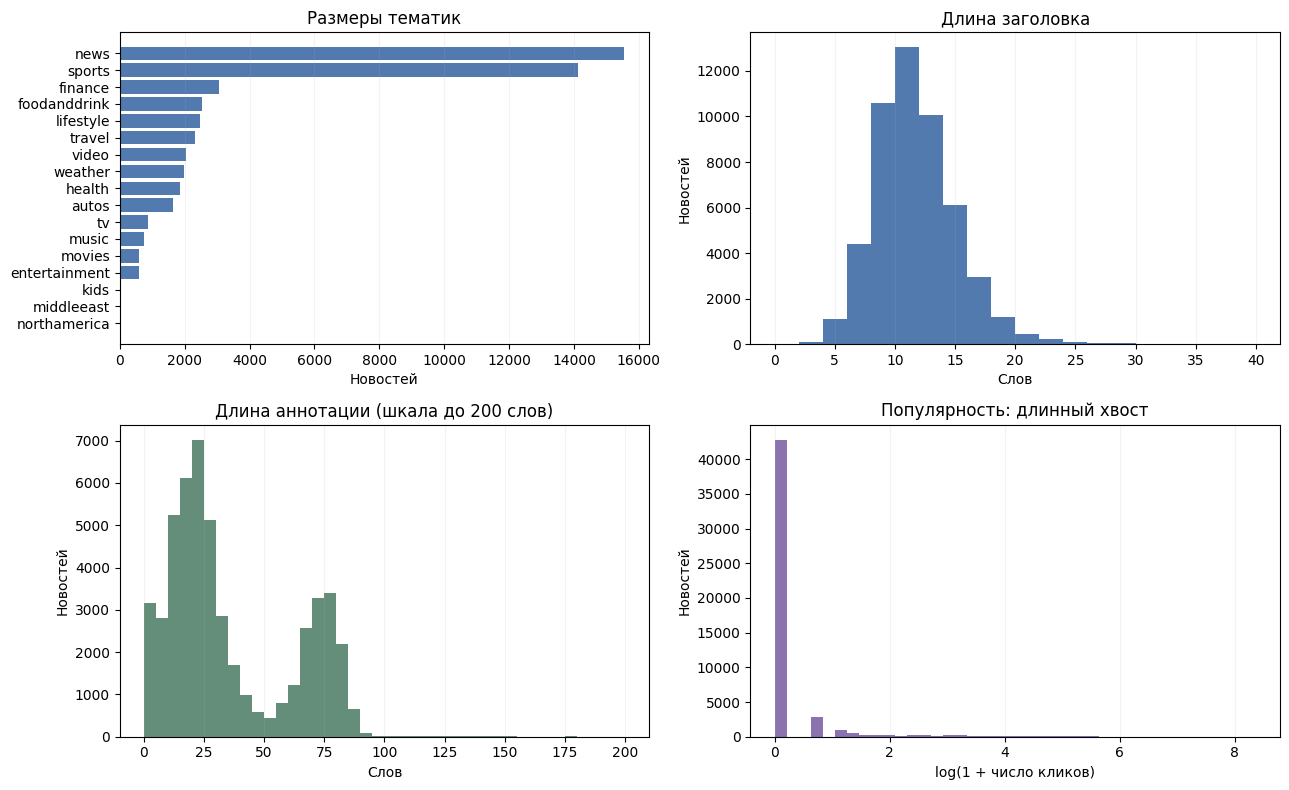

Без аннотации: 5.2%; без кликов в показах: 84.9%.
Нулевые клики в показах не означают отсутствия новости в предшествующей истории.


In [5]:
topic_sizes = catalog_eda.group_by('category').agg(pl.len().alias('news'), pl.col('abstract_missing').mean().alias('missing_abstract_fraction'), pl.col('click_count').sum().alias('clicks')).sort('news', descending=True)
missing_fraction = catalog_eda['abstract_missing'].mean()
zero_click_fraction = (catalog_eda['click_count'] == 0).mean()
display(pl.DataFrame({'Показатель': ['Новостей', 'Категорий', 'Пар категория–подкатегория', 'Без аннотации, %', 'Без кликов в показах, %'], 'Значение': [float(catalog_eda.height), float(catalog_eda['category'].n_unique()), float(catalog_eda.select(pl.struct('category', 'subcategory').n_unique()).item()), 100 * missing_fraction, 100 * zero_click_fraction]}))
display(topic_sizes)
display(catalog_eda.select([pl.col(column).median().alias(column + '_median') for column in ['title_words', 'abstract_words', 'click_count']]))
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
ordered_topics = topic_sizes.sort('news')
axes[0, 0].barh(ordered_topics['category'], ordered_topics['news'], color='#527aaf')
axes[0, 0].set(title='Размеры тематик', xlabel='Новостей')
axes[0, 1].hist(catalog_eda['title_words'], bins=np.arange(0, 42, 2), color='#527aaf')
axes[0, 1].set(title='Длина заголовка', xlabel='Слов', ylabel='Новостей')
axes[1, 0].hist(catalog_eda['abstract_words'], bins=np.arange(0, 205, 5), color='#648e7a')
axes[1, 0].set(title='Длина аннотации (шкала до 200 слов)', xlabel='Слов', ylabel='Новостей')
axes[1, 1].hist(np.log1p(catalog_eda['click_count'].to_numpy()), bins=40, color='#8b73af')
axes[1, 1].set(title='Популярность: длинный хвост', xlabel='log(1 + число кликов)', ylabel='Новостей')
for ax in axes.flat:
    ax.grid(alpha=0.15, axis='x')
fig.tight_layout()
plt.show()
print(f'Без аннотации: {missing_fraction:.1%}; без кликов в показах: {zero_click_fraction:.1%}.')
print('Нулевые клики в показах не означают отсутствия новости в предшествующей истории.')

Показатель,Значение
str,f64
"""Пользователей""",50000.0
"""Уникальных позитивных пар""",1.146909e6
"""Пользовательских показов""",156965.0
"""Экспозиций новостей""",5.83085e6
"""CTR, %""",4.050524
"""Пользователей с ≥10 позитивами, %""",65.574


date,shows,exposures,clicks,ctr
str,u32,i64,i64,f64
"""2019-11-09""",13570,523102,20152,0.038524
"""2019-11-10""",15048,518745,21756,0.04194
"""2019-11-11""",32799,1162970,48029,0.041299
"""2019-11-12""",33654,1176453,51499,0.043775
"""2019-11-13""",31624,1229373,47938,0.038994
"""2019-11-14""",30270,1220207,46806,0.038359


history_size_p50,history_size_p90,history_size_p99,exposures_p50,exposures_p90,exposures_p99,clicks_p50,clicks_p90,clicks_p99
f64,f64,f64,f64,f64,f64,f64,f64,f64
19.0,76.0,188.0,24.0,91.0,165.0,1.0,3.0,6.0


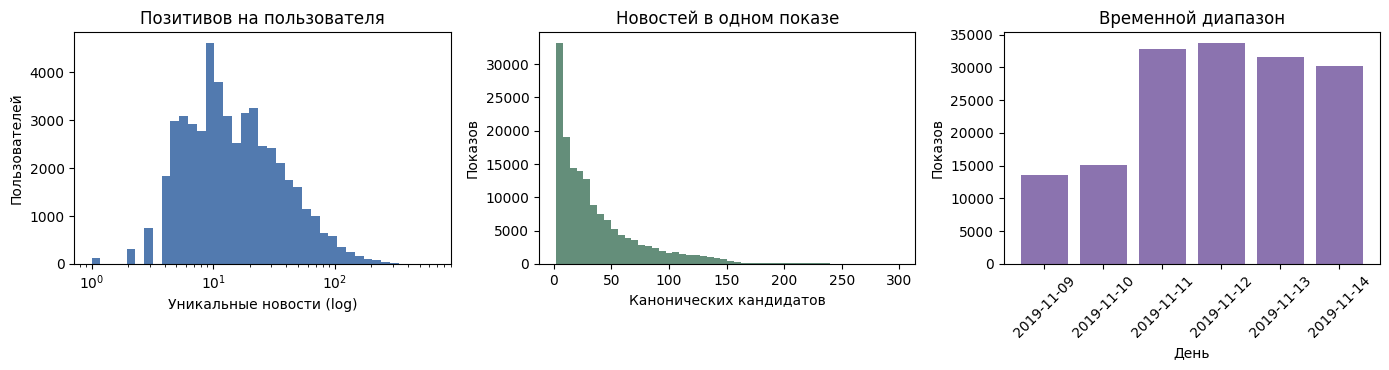

Поведенческие признаки ранжировщика будут заморожены до 10 ноября; последующие дни задают train, validation и test.


In [6]:
behaviors_eda = read_behaviors(DATA / 'raw' / 'MINDsmall_train.zip')
news_index_eda = {row['news_id']: i for i, row in enumerate(resources.rows)}
alias_index_eda = {old: news_index_eda[new] for old, new in canonical_ids.items()}
behavior_rows_eda = []
for record in behaviors_eda:
    exposed = shown_items(record, alias_index_eda)
    history = {alias_index_eda[item] for item in record['history'].split() if item in alias_index_eda}
    behavior_rows_eda.append({'date': record['timestamp'][:10], 'history_size': len(history), 'exposures': len(exposed), 'clicks': sum(exposed.values())})
behavior_eda = pl.DataFrame(behavior_rows_eda)
daily_eda = behavior_eda.group_by('date').agg(pl.len().alias('shows'), pl.col('exposures').sum(), pl.col('clicks').sum()).sort('date').with_columns((pl.col('clicks') / pl.col('exposures')).alias('ctr'))
positive_lengths = np.diff(resources.user_item.indptr)
display(pl.DataFrame({'Показатель': ['Пользователей', 'Уникальных позитивных пар', 'Пользовательских показов', 'Экспозиций новостей', 'CTR, %', 'Пользователей с ≥10 позитивами, %'], 'Значение': [float(len(resources.user_ids)), float(resources.user_item.nnz), float(behavior_eda.height), float(behavior_eda['exposures'].sum()), 100 * behavior_eda['clicks'].sum() / behavior_eda['exposures'].sum(), 100 * float((positive_lengths >= 10).mean())]}))
display(daily_eda)
display(behavior_eda.select([pl.col(column).quantile(q).alias(f'{column}_p{int(100 * q)}') for column in ['history_size', 'exposures', 'clicks'] for q in [0.5, 0.9, 0.99]]))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hist(positive_lengths, bins=np.logspace(0, np.log10(positive_lengths.max() + 1), 40), color='#527aaf')
axes[0].set(xscale='log', title='Позитивов на пользователя', xlabel='Уникальные новости (log)', ylabel='Пользователей')
axes[1].hist(behavior_eda['exposures'], bins=50, color='#648e7a')
axes[1].set(title='Новостей в одном показе', xlabel='Канонических кандидатов', ylabel='Показов')
axes[2].bar(daily_eda['date'], daily_eda['shows'], color='#8b73af')
axes[2].tick_params(axis='x', labelrotation=45)
axes[2].set(title='Временной диапазон', xlabel='День', ylabel='Показов')
fig.tight_layout()
plt.show()
print('Поведенческие признаки ранжировщика будут заморожены до 10 ноября; последующие дни задают train, validation и test.')

split,pairs,positive,positive_fraction,negative
str,u32,u32,f64,u32
"""train""",9691,4080,0.421009,5611
"""validation""",2000,301,0.1505,1699
"""test""",1996,284,0.142285,1712


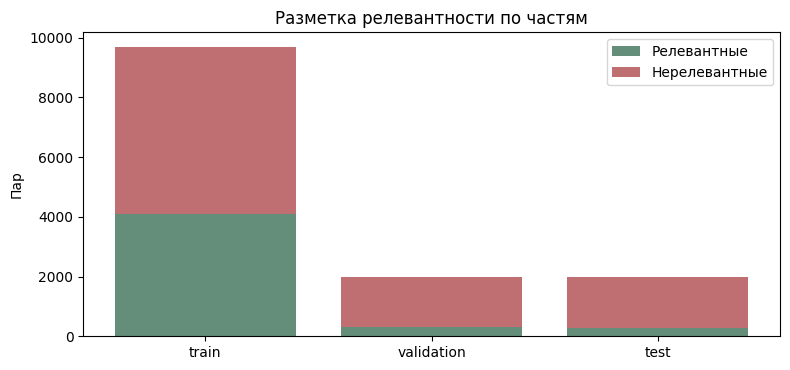

Учитываем различие баланса train и отложенных частей.
Поэтому баланс train не переносится на весь каталог или новую выдачу; precision измеряем отдельно на отложенной разметке.


In [7]:
label_balance_eda = labelled.group_by('split').agg(pl.len().alias('pairs'), pl.col('relevant').sum().alias('positive'), pl.col('relevant').mean().alias('positive_fraction')).with_columns((pl.col('pairs') - pl.col('positive')).alias('negative')).sort(pl.col('split').replace_strict({'train': 0, 'validation': 1, 'test': 2}))
display(label_balance_eda)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(label_balance_eda['split'], label_balance_eda['positive'], label='Релевантные', color='#648e7a')
ax.bar(label_balance_eda['split'], label_balance_eda['negative'], bottom=label_balance_eda['positive'], label='Нерелевантные', color='#bf6f72')
ax.set(title='Разметка релевантности по частям', ylabel='Пар')
ax.legend()
fig.tight_layout()
plt.show()
print('Учитываем различие баланса train и отложенных частей.')
print('Поэтому баланс train не переносится на весь каталог или новую выдачу; precision измеряем отдельно на отложенной разметке.')

**Что EDA означает для следующих этапов**

- Тематики news и sports занимают около 58.8% каталога. При сборе разметки нужны квоты, чтобы малые темы тоже были представлены.
- У 5.2% новостей нет аннотации; медианная длина заголовка — 11 слов, аннотации — 25 слов. Заголовок остаётся обязательным источником контента.
- У 84.9% новостей нет кликов в наблюдавшихся показах. Они могут встречаться в предшествующих историях, поэтому это не доля полностью холодных объектов. Контентные признаки позволяют работать и со слабой поведенческой статистикой.
- В показе медианно 24 канонические новости и один клик; CTR по экспозициям — около 4.05%. Unclicked — доступный, но шумный loser для pairwise-обучения.
- 65.6% пользователей имеют не менее десяти уникальных позитивов: демонстрация с десятью anchors возможна для значительной части пользователей, но не описывает короткие истории.
- Доля релевантных пар в train — 42.1%, в validation — 15.1%, в test — 14.2%. Различие баланса учитываем при оценке: качество и выбор порога проверяем на отложенных частях.


## 2. Три пространства объектов

![У каждого объекта есть семантический, лексический и коллаборативный вектор](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/03_spaces.png)

**Вход:** общий каталог и бинарная матрица R. **Выход:** три массива векторов с одинаковым порядком ID.
Каждое пространство даёт собственный набор соседей, поэтому источники могут дополнять друг друга.

| Источник | Представление | Размерность | Что сближает объекты |
|---|---|---:|---|
| dense | MiniLM, заголовок + аннотация | 384 | Семантика текста |
| lexical | TF-IDF слов/биграмм → SVD | 128 | Термины и имена |
| als | implicit ALS item_factors | 64 | Аудитория и предпочтения |

Для любого ненулевого вектора $v_m(i)$ применяем:

$$
z_m(i)=\frac{v_m(i)}{\|v_m(i)\|_2},\qquad
\cos(v_m(A),v_m(i))=z_m(A)^\top z_m(i).
$$

Поэтому все три FAISS-индекса ищут максимальный inner product нормированных векторов.
Нулевые векторы не индексируем; нулевой query возвращает пустую выдачу.

### 2.1. Семантика: MiniLM

![Текст превращается в нормированный 384-мерный вектор](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/04_dense.png)

Вход энкодера — заголовок и аннотация. MiniLM превращает их в один семантический вектор новости.

$$
e(i)=Encoder(text_i)\inR^{384},\qquad
z_{dense}(i)=\frac{e(i)}{\|e(i)\|_2}.
$$

Обучение энкодера в семинар не входит. Соседство по смыслу — источник кандидатов;
близость вектора сама по себе не задаёт LLM-метку релевантности.

### 2.2. Лексика: TF-IDF и SVD

![Точный TF-IDF проецируется в SVD128 для поиска](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/05_lexical.png)

Словарь состоит из слов и биграмм. Исключаем стоп-слова, слишком редкие и слишком частые термы. Для терма t и N документов используется sklearn smooth IDF:

$$
idf_t=\log\frac{N+1}{df_t+1}+1,\quad
\widetilde x_{it}=count(t,i)\,idf_t,\quad
x_i=\frac{\widetilde x_i}{\|\widetilde x_i\|_2}.
$$

Пусть $X\approx U_{128}\Sigma_{128}V_{128}^\top$ — truncated SVD. Тогда:

$$
v_{lexical}(i)=x_iV_{128},\qquad z_{lexical}(i)=\frac{v_{lexical}(i)}{\|v_{lexical}(i)\|_2}.
$$

FAISS использует компактный SVD128. Признак `tfidf_similarity` для CatBoost считается
по **исходному sparse TF-IDF**: $x_A^\top x_i$. Это два разных сходства.

### 2.3. Предпочтения: implicit ALS

![Из бинарных взаимодействий обучаются item_factors для i2i-поиска](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/06_als.png)

ALS факторизует взаимодействия через user factors $p_u$ и item factors $q_i$:

$$
\min_{P,Q}\sum_{u,i}c_{ui}\left(R_{ui}-p_u^\top q_i\right)^2
+\lambda\left(\sum_u\|p_u\|_2^2+\sum_i\|q_i\|_2^2\right).
$$

Наблюдавшимся позитивам даём больший вес через $c_{ui}$; регуляризация ограничивает сложность представлений.
Поочерёдно обновляем пользовательские векторы при фиксированных объектных и наоборот.

Обучение восстанавливает $p_u^\top q_i$, но наш **i2i-поиск** сравнивает item factors:

$$
z_{als}(i)=\frac{q_i}{\|q_i\|_2},\qquad s_{als}(A,i)=z_{als}(A)^\top z_{als}(i).
$$

Без обучающих взаимодействий item-вектор может быть нулевым: такие 11 043 объекта не попадают в ALS-индекс.
В нём остаётся 39 408 объектов; два текстовых индекса содержат все 50 451.


In [8]:
def normalize_rows(vectors):
    values = np.array(vectors, dtype=np.float32, copy=True, order='C')
    if not np.isfinite(values).all():
        raise ValueError('Non-finite index vectors')
    lengths = np.linalg.norm(values, axis=1)
    valid = lengths > 1e-12
    values[valid] /= lengths[valid, None]
    values[~valid] = 0
    return (values, valid)

def prepare_vectors(resources, output_dir, seed=42):
    from implicit.als import AlternatingLeastSquares
    output_dir = Path(output_dir)
    settings = dict(resources=resources.fingerprint, lexical_dimensions=128, als_factors=64, als_iterations=30, als_regularization=0.1, als_alpha=20, seed=seed, implicit_version=version('implicit'))
    info_path = output_dir / 'representations.json'
    info = json.loads(info_path.read_text()) if info_path.exists() else None
    if info and info.get('settings') == settings:
        vectors = {name: np.load(output_dir / f'{name}_vectors.npy') for name in ['dense', 'lexical', 'als']}
        return (vectors, info)
    started = perf_counter()
    with threadpool_limits(limits=4):
        projector = TruncatedSVD(n_components=128, n_iter=5, random_state=seed)
        lexical = projector.fit_transform(resources.tfidf)
    joblib.dump(projector, output_dir / 'lexical_svd.joblib')
    lexical_seconds = perf_counter() - started
    started = perf_counter()
    with threadpool_limits(limits=1, user_api='blas'):
        als = AlternatingLeastSquares(factors=64, regularization=0.1, iterations=30, alpha=20, random_state=seed, num_threads=4, use_gpu=False)
        als.fit(resources.user_item, show_progress=False)
    if als.item_factors.shape[0] != len(resources.rows):
        raise ValueError('ALS factors are not aligned with catalog IDs')
    als.save(str(output_dir / 'als_model.npz'))
    als_seconds = perf_counter() - started
    vectors = {name: normalize_rows(values)[0] for name, values in [('dense', resources.embeddings), ('lexical', lexical), ('als', als.item_factors)]}
    for name, values in vectors.items():
        np.save(output_dir / f'{name}_vectors.npy', values)
    info = dict(settings=settings, lexical_seconds=lexical_seconds, als_seconds=als_seconds, lexical_explained_variance=float(projector.explained_variance_ratio_.sum()), spaces={name: dict(dimensions=values.shape[1], nonzero_rows=int(normalize_rows(values)[1].sum())) for name, values in vectors.items()})
    info_path.write_text(json.dumps(info, indent=2) + '\n')
    return (vectors, info)

def make_features(resources, vectors):
    features = PairFeatures(resources.rows, vectors['dense'], resources.tfidf, resources.user_item, item_factors=vectors['als'])
    features.fingerprint = hashlib.sha256((features.fingerprint + resources.fingerprint).encode()).hexdigest()
    return features

In [9]:
vectors, representation_info = prepare_vectors(resources, ARTIFACTS, seed=SEED)
display(pl.DataFrame([{'source': name, **values} for name, values in representation_info['spaces'].items()]))
print(f"Обучение ALS: {representation_info['als_seconds']:.1f} с; TF-IDF/SVD: {representation_info['lexical_seconds']:.1f} с")

source,dimensions,nonzero_rows
str,i64,i64
"""dense""",384,50451
"""lexical""",128,50451
"""als""",64,39408


Обучение ALS: 23.5 с; TF-IDF/SVD: 21.3 с


## 3. Модель релевантности

![Объекты преобразуются в симметричные признаки пары](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/07_features.png)

**Вход:** пара (A,i), контент, метаданные, векторы и обучающие взаимодействия.
**Выход:** 17 числовых признаков $\phi(A,i)=\phi(i,A)$.
Симметрия соответствует вопросу: «есть ли содержательная связь между двумя объектами?»

Три признака — cosine в MiniLM, точном TF-IDF и ALS. Для аудиторного сходства пусть
$n_A,n_i$ — размеры аудиторий, $n_{Ai}$ — число общих пользователей:

$$
s_{cf}(A,i)=1[n_{Ai}\ge2]\,
\frac{n_{Ai}}{\sqrt{n_A n_i}}\,\frac{n_{Ai}}{n_{Ai}+10}.
$$

При нулевом знаменателе берём 0. Shrinkage $n_{Ai}/(n_{Ai}+10)$ уменьшает вес слабой статистики.
Отдельный признак — $\log(1+n_{Ai})$.
Для множеств сущностей и слов заголовков используем Jaccard:

$$
J(S_A,S_i)=\frac{|S_A\cap S_i|}{\max(1,|S_A\cup S_i|)}.
$$

Остальные признаки: число общих сущностей, совпадение категории/подкатегории,
минимум/максимум длин заголовков и аннотаций, число непустых аннотаций,
минимум/максимум $\log(1+click\_count)$.
ID, источник поиска, этап семплирования и объяснение LLM в признаки не входят.

### 3.1. Обучение модели релевантности

![Train-пары обучают Logloss, validation выбирает число деревьев, test оценивает модель](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/08_relevance_train.png)

Target $y_{Ai}\in\{0,1\}$ — готовая LLM-разметка содержательной связи.
CatBoost строит ансамбль деревьев $f_{rel}$ и возвращает score через sigmoid:

$$
f_{rel}(\phi)=\sum_{t=1}^{T}\eta h_t(\phi),\qquad
r(A,i)=\sigma(f_{rel}(\phi(A,i))),\qquad \sigma(x)=\frac1{1+e^{-x}}.
$$

Обучение минимизирует бинарный Logloss:

$$
L_{rel}=-\frac1{n}\sum_{(A,i)}\left[y_{Ai}\log r(A,i)+(1-y_{Ai})\log(1-r(A,i))\right].
$$

Обучение контролируем по качеству на validation. Test оставляем для итоговой оценки.
Разделение по anchors проверяет обобщение на новые anchors; весь каталог при этом остаётся общим.


**Признаки модели релевантности**

| Признак | Как считается |
|---|---|
| `dense_similarity` | Cosine семантических векторов текстов |
| `tfidf_similarity` | Cosine исходных TF-IDF векторов |
| `als_similarity` | Cosine объектных векторов ALS |
| `collaborative_similarity` | Сходство аудиторий с ослаблением малых пересечений |
| `log_shared_users` | Логарифм числа общих пользователей: $\log(1+n_{Ai})$ |
| `same_category` | Совпадает ли категория |
| `same_subcategory` | Совпадают ли категория и подкатегория |
| `shared_entity_count` | Число общих сущностей |
| `entity_jaccard` | Jaccard множеств сущностей |
| `title_jaccard` | Jaccard множеств слов заголовков |
| `min_title_words`, `max_title_words` | Меньшая и большая длина заголовков |
| `min_abstract_words`, `max_abstract_words` | Меньшая и большая длина аннотаций |
| `abstract_count` | Сколько из двух объектов имеют аннотацию |
| `min_log_popularity`, `max_log_popularity` | Меньшее и большее значение $\log(1+clicks)$ |

Это 17 симметричных числовых признаков. В статической демонстрации их поведенческая часть
использует обучающий снимок взаимодействий. В оценке будущих кликов обе модели используют только ранний снимок.


In [10]:
FEATURE_NAMES = ['dense_similarity', 'tfidf_similarity', 'als_similarity', 'collaborative_similarity', 'log_shared_users', 'same_category', 'same_subcategory', 'shared_entity_count', 'entity_jaccard', 'title_jaccard', 'min_title_words', 'max_title_words', 'min_abstract_words', 'max_abstract_words', 'abstract_count', 'min_log_popularity', 'max_log_popularity']
FEATURE_VERSION = 2

class PairFeatures:

    def __init__(self, rows, embeddings, tfidf, user_item, item_factors=None):
        self.rows = rows
        self.embeddings = embeddings
        self.item_factors = item_factors
        self.tfidf = tfidf.tocsr()
        self.item_user = user_item.T.tocsr()
        self.frequency = np.asarray(user_item.sum(axis=0)).ravel()
        self.index = {row['news_id']: i for i, row in enumerate(rows)}
        self.categories = np.array([r['category'] for r in rows])
        self.subcategories = np.array([r['subcategory'] for r in rows])
        self.entities = [set(r['entities']) for r in rows]
        self.title_tokens = [set(re.findall('[a-z0-9]+', r['title'].casefold())) for r in rows]
        self.title_lengths = np.array([len(re.findall('\\w+', r['title'])) for r in rows])
        self.abstract_lengths = np.array([len(re.findall('\\w+', r['abstract'])) for r in rows])
        self.popularity = np.log1p([r['click_count'] for r in rows])
        fingerprint = hashlib.sha256(json.dumps(rows, sort_keys=True, ensure_ascii=False).encode())
        fingerprint.update(np.ascontiguousarray(embeddings).tobytes())
        if item_factors is not None:
            fingerprint.update(np.ascontiguousarray(item_factors).tobytes())
        self.fingerprint = fingerprint.hexdigest()

    def frame(self, anchors, candidates):
        anchors, candidates = (np.asarray(anchors, dtype=np.int64), np.asarray(candidates, dtype=np.int64))
        if len(anchors) != len(candidates):
            raise ValueError('Pair arrays have different lengths')
        if not len(anchors):
            return pl.DataFrame(schema={name: pl.Float64 for name in FEATURE_NAMES})
        chunks = []
        for offset in range(0, len(anchors), 4096):
            a, b = (anchors[offset:offset + 4096], candidates[offset:offset + 4096])
            dense = np.einsum('ij,ij->i', self.embeddings[a], self.embeddings[b])
            als = np.einsum('ij,ij->i', self.item_factors[a], self.item_factors[b]) if self.item_factors is not None else np.zeros(len(a))
            lexical = np.asarray(self.tfidf[a].multiply(self.tfidf[b]).sum(axis=1)).ravel()
            overlap = np.asarray(self.item_user[a].multiply(self.item_user[b]).sum(axis=1)).ravel()
            denominator = np.sqrt(self.frequency[a] * self.frequency[b])
            collaborative = np.divide(overlap, denominator, out=np.zeros_like(overlap), where=denominator > 0)
            collaborative *= overlap / (overlap + 10)
            collaborative[overlap < 2] = 0
            entity_shared, entity_jaccard, title_jaccard = ([], [], [])
            for i, j in zip(a, b):
                common = len(self.entities[i] & self.entities[j])
                entity_shared.append(common)
                entity_jaccard.append(common / max(1, len(self.entities[i] | self.entities[j])))
                title_jaccard.append(len(self.title_tokens[i] & self.title_tokens[j]) / max(1, len(self.title_tokens[i] | self.title_tokens[j])))
            same_category = self.categories[a] == self.categories[b]
            values = dict(dense_similarity=dense, tfidf_similarity=lexical, als_similarity=als, collaborative_similarity=collaborative, log_shared_users=np.log1p(overlap), same_category=same_category.astype(float), same_subcategory=(same_category & (self.subcategories[a] == self.subcategories[b])).astype(float), shared_entity_count=entity_shared, entity_jaccard=entity_jaccard, title_jaccard=title_jaccard, min_title_words=np.minimum(self.title_lengths[a], self.title_lengths[b]), max_title_words=np.maximum(self.title_lengths[a], self.title_lengths[b]), min_abstract_words=np.minimum(self.abstract_lengths[a], self.abstract_lengths[b]), max_abstract_words=np.maximum(self.abstract_lengths[a], self.abstract_lengths[b]), abstract_count=(self.abstract_lengths[a] > 0).astype(int) + (self.abstract_lengths[b] > 0), min_log_popularity=np.minimum(self.popularity[a], self.popularity[b]), max_log_popularity=np.maximum(self.popularity[a], self.popularity[b]))
            chunks.append(pl.DataFrame(values).select(FEATURE_NAMES).cast(pl.Float64))
        return pl.concat(chunks)

def threshold_curve(labels, scores):
    y, p = (np.asarray(labels, dtype=int), np.asarray(scores, dtype=float))
    if len(y) != len(p) or not len(y) or (not np.isfinite(p).all()) or (not np.isin(y, [0, 1]).all()):
        raise ValueError('Invalid binary labels or scores')
    order = np.argsort(-p, kind='stable')
    y, p = (y[order], p[order])
    ends = np.r_[np.flatnonzero(np.diff(p)), len(p) - 1]
    kept = ends + 1
    positive = np.cumsum(y)[ends]
    return pl.DataFrame(dict(threshold=p[ends], kept=kept, true_positive=positive, precision=positive / kept, recall=positive / max(1, y.sum()))).with_columns((2 * pl.col('precision') * pl.col('recall') / (pl.col('precision') + pl.col('recall'))).fill_nan(0).alias('f1'))

def choose_threshold(labels, scores, target_precision=0.9, min_kept=50):
    curve = threshold_curve(labels, scores)
    eligible = curve.filter((pl.col('precision') >= target_precision) & (pl.col('kept') >= min_kept))
    if eligible.is_empty():
        return dict(threshold=float(np.nextafter(1.0, np.inf)), feasible=False, kept=0, precision=None, recall=0.0, target_precision=target_precision, min_kept=min_kept)
    row = eligible.sort(['kept', 'threshold'], descending=[True, False]).row(0, named=True)
    return dict(row, feasible=True, target_precision=target_precision, min_kept=min_kept)

def classification_metrics(labels, scores, threshold):
    y, p = (np.asarray(labels, dtype=int), np.asarray(scores))
    predicted = p >= threshold
    return dict(rows=len(y), positives=int(y.sum()), roc_auc=float(roc_auc_score(y, p)), average_precision=float(average_precision_score(y, p)), precision=float(precision_score(y, predicted, zero_division=0)), recall=float(recall_score(y, predicted, zero_division=0)), f1=float(f1_score(y, predicted, zero_division=0)), kept=int(predicted.sum()), true_positive=int(np.sum(predicted & (y == 1))), false_positive=int(np.sum(predicted & (y == 0))), false_negative=int(np.sum(~predicted & (y == 1))), true_negative=int(np.sum(~predicted & (y == 0))))

def operating_threshold(labels, scores, fixed=None, target_precision=0.9, min_kept=50, rule='f1'):
    if fixed is None:
        if rule == 'f1':
            row = threshold_curve(labels, scores).sort(['f1', 'threshold'], descending=[True, True]).row(0, named=True)
            return dict(row, selection='validation_f1', feasible=True)
        if rule == 'precision':
            return dict(choose_threshold(labels, scores, target_precision, min_kept), selection='validation_precision')
        raise ValueError('Threshold rule must be f1 or precision')
    if not 0 <= fixed <= 1:
        raise ValueError('Fixed threshold must be in [0, 1]')
    y, p = (np.asarray(labels, dtype=int), np.asarray(scores))
    kept = p >= fixed
    return dict(threshold=float(fixed), selection='fixed', feasible=True, kept=int(kept.sum()), precision=float(precision_score(y, kept, zero_division=0)), recall=float(recall_score(y, kept, zero_division=0)), f1=float(f1_score(y, kept, zero_division=0)))

def shap_contributions(model, matrix):
    from catboost import Pool
    values = np.asarray(model.get_feature_importance(Pool(matrix.to_numpy()), type='ShapValues', thread_count=4), dtype=float)
    if values.ndim != 2 or values.shape[1] != matrix.width + 1:
        raise ValueError('Expected SHAP values for a binary classifier or scalar ranker')
    contributions, baseline = (values[:, :-1], values[:, -1])
    importance = pl.DataFrame(dict(feature=matrix.columns, mean_abs_shap=np.abs(contributions).mean(axis=0))).sort('mean_abs_shap', descending=True)
    return dict(values=contributions, base_value=baseline, importance=importance)

In [11]:
features = make_features(resources, vectors)
example_pairs = labelled.head(4)
display(features.frame([features.index[x] for x in example_pairs['anchor_id']], [features.index[x] for x in example_pairs['candidate_id']]))

dense_similarity,tfidf_similarity,als_similarity,collaborative_similarity,log_shared_users,same_category,…,max_title_words,min_abstract_words,max_abstract_words,abstract_count,min_log_popularity,max_log_popularity
f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64
0.44012,0.0,0.300222,0.0,0.0,0.0,…,13.0,22.0,25.0,2.0,0.0,5.866468
0.478415,0.121275,0.40551,0.025404,2.397895,0.0,…,10.0,25.0,34.0,2.0,0.0,5.866468
0.441419,0.063707,-0.025143,0.0,0.0,0.0,…,11.0,22.0,25.0,2.0,0.0,5.866468
0.488176,0.149858,0.0,0.0,0.0,0.0,…,16.0,0.0,25.0,1.0,0.0,5.866468


In [12]:
rel_matrix = features.frame([features.index[item] for item in labelled['anchor_id']], [features.index[item] for item in labelled['candidate_id']]).to_numpy()
rel_targets = labelled['relevant'].cast(pl.UInt8).to_numpy()
rel_parts = {name: np.flatnonzero(labelled['split'].to_numpy() == name) for name in ['train', 'validation', 'test']}
from catboost import CatBoostClassifier
model = CatBoostClassifier(iterations=1200, depth=6, learning_rate=0.05, loss_function='Logloss', eval_metric='AUC', l2_leaf_reg=5, random_seed=SEED, thread_count=4, allow_writing_files=False)
model.fit(rel_matrix[rel_parts['train']], rel_targets[rel_parts['train']], eval_set=(rel_matrix[rel_parts['validation']], rel_targets[rel_parts['validation']]), early_stopping_rounds=80, verbose=False)
rel_scores = model.predict_proba(rel_matrix)[:, 1]
valid_rows = rel_parts['validation']
rel_choice = operating_threshold(rel_targets[valid_rows], rel_scores[valid_rows], fixed=FIXED_THRESHOLD)
classification = {'threshold': rel_choice, 'tree_count': model.tree_count_, 'metrics': {name: classification_metrics(rel_targets[indices], rel_scores[indices], rel_choice['threshold']) for name, indices in rel_parts.items()}}
labelled.with_columns(pl.Series('relevance_score', rel_scores)).write_parquet(ARTIFACTS / 'labelled_predictions.parquet')
threshold_curve(rel_targets[valid_rows], rel_scores[valid_rows]).write_parquet(ARTIFACTS / 'validation_thresholds.parquet')
model.save_model(str(ARTIFACTS / 'relevance_model.cbm'))
(ARTIFACTS / 'classification_report.json').write_text(json.dumps(classification, indent=2))
rel_importance = pl.DataFrame({'feature': FEATURE_NAMES, 'importance': model.get_feature_importance()}).sort('importance', descending=True)
rel_importance.write_csv(ARTIFACTS / 'feature_importance.csv')
display(pl.DataFrame([{'split': name, **metrics} for name, metrics in classification['metrics'].items()]).select('split', 'rows', 'roc_auc', 'average_precision', 'precision', 'recall', 'f1', 'true_positive', 'false_positive', 'false_negative'))
display(rel_importance)

split,rows,roc_auc,average_precision,precision,recall,f1,true_positive,false_positive,false_negative
str,i64,f64,f64,f64,f64,f64,i64,i64,i64
"""train""",9691,0.980497,0.975521,0.973318,0.804657,0.880988,3283,90,797
"""validation""",2000,0.920125,0.704413,0.866071,0.322259,0.469734,97,15,204
"""test""",1996,0.911573,0.688505,0.882979,0.292254,0.439153,83,11,201


feature,importance
str,f64
"""dense_similarity""",37.992688
"""entity_jaccard""",10.65659
"""tfidf_similarity""",10.03423
"""max_abstract_words""",6.809783
"""min_abstract_words""",5.712868
"""shared_entity_count""",5.394548
…,…
"""same_category""",2.100165
"""same_subcategory""",1.939281


### 3.2. Пары с высоким score: что увидела модель?

![Отложенные пары сортируются по score, затем их тексты и метки разбираются вместе](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/25_relevance_examples.png)

Посмотрим на пары **из test**, которые модель не видела при обучении.
Сначала покажем несколько максимальных scores с заголовками и фрагментами аннотаций.
Проверим: связаны ли тексты конкретным событием, темой или сущностью в общем контексте?
Затем отдельно разберём высокие scores для пар, размеченных как нерелевантные.

Высокий score — уверенность модели по её признакам, а не доказательство правильности.
Разбор может показать как ошибку модели, так и пограничную LLM-метку.
Примеры test здесь служат иллюстрацией уже зафиксированной модели; настройку выполняем по validation.


In [13]:
from IPython.display import Markdown
from html import escape
scored_test_pairs = pl.read_parquet(ARTIFACTS / 'labelled_predictions.parquet').filter(pl.col('split') == 'test').sort('relevance_score', descending=True)
news_for_examples = {row['news_id']: row for row in resources.rows}

def display_relevance_pairs(frame, heading):
    display(Markdown(f'**{heading}**'))
    if frame.is_empty():
        print('Таких пар в выбранной части нет.')
    for row in frame.iter_rows(named=True):
        anchor = news_for_examples[row['anchor_id']]
        candidate = news_for_examples[row['candidate_id']]
        label = 'релевантна' if row['relevant'] else 'нерелевантна'
        text = f"**Score: {row['relevance_score']:.3f} · LLM-метка: {label}**\n\n**Anchor:** {escape(anchor['title'])}\n\n{escape(anchor['abstract'][:350])}\n\n**Кандидат:** {escape(candidate['title'])}\n\n{escape(candidate['abstract'][:350])}"
        display(Markdown(text))
display_relevance_pairs(scored_test_pairs.head(4), 'Наиболее высокие scores')
display_relevance_pairs(scored_test_pairs.filter((pl.col('relevance_score') >= FIXED_THRESHOLD) & ~pl.col('relevant')).head(2), 'Уверенные расхождения с разметкой')

**Наиболее высокие scores**

**Score: 0.995 · LLM-метка: релевантна**

**Anchor:** Split Supreme Court appears ready to allow Trump to end DACA

Democrats are promising to stick with young immigrants as the Supreme Court&#x27;s conservative majority seems prepared to allow the Trump administration to end a program that allows them to work legally in the US and protects them from deportation. (Nov. 12)

**Кандидат:** Supreme Court weighs fate of DACA, 700,000 young immigrants

The Supreme Court hears oral arguments in a case challenging President Trump&#x27;s controversial 2017 decision to end Deferred Action for Childhood Arrivals, or DACA.

**Score: 0.993 · LLM-метка: релевантна**

**Anchor:** Wisconsin bus driver saves children wandering in snow, as deadly Arctic air mass grips US

As bitter cold took hold across the Midwest earlier this week, a sharp-eyed bus driver in Wisconsin was credited with helping rescue two children who were very underdressed for the weather conditions.

**Кандидат:** Children, ages 2 and 6, found wandering in the snow rescued by Wisconsin bus driver

The bus driver took off her coat to cover and help warm the 2-year-old&#x27;s bare legs.

**Score: 0.991 · LLM-метка: релевантна**

**Anchor:** Dallas Convention Center To Open As Temporary Homeless Shelter

DALLAS (1080 KRLD) - Due to the cold over the next couple of nights, Dallas is opening the Kay Bailey Hutchison Convention Center as a temporary shelter for the homeless. The doors will open this afternoon 5:30 p.m. when it&#x27;s expected the temperatures have dropped into the 30s. Same time Tuesday.

**Кандидат:** Homelessness: No Easy Fixes… Convention Center Again Reopens As Emergency Shelter

In Dallas, with freezing temperatures expected again overnight, homeless advocates are applauding the city&#x27;s decision to open the Kay Bailey Hutchison Convention Center as an emergency shelter.

**Score: 0.990 · LLM-метка: релевантна**

**Anchor:** LSU is new No. 1 in Amway Coaches Poll after Alabama victory, while Minnesota joins top 10

LSU has taken the No. 1 spot in the Amway Coaches Poll after beating then-No. 1 Alabama. Minnesota moved in the top 10 after beating Penn State.

**Кандидат:** Coaches poll: LSU jumps Ohio State, Oklahoma to No. 3; Georgia falls

LSU moved up three spots to No. 3 in the Amway Coaches Poll behind Alabama and Clemson. Georgia dropped seven spots after losing to South Carolina.

**Уверенные расхождения с разметкой**

**Score: 0.977 · LLM-метка: нерелевантна**

**Anchor:** 30 best Netflix shows for binge watching over the holidays

The unprecedented density of the catalog of films and television shows on Netflix provides plenty of content for families to binge-watch during this holiday season. See what Stacker has to say about the top 30 ranked television shows you can stream online.

**Кандидат:** 15 Netflix Movies We&#x27;re Pumped To Watch In November

Some of Netflix&#x27;s best new titles are just in time for binge-watching season.

**Score: 0.962 · LLM-метка: нерелевантна**

**Anchor:** LSU is new No. 1 in Amway Coaches Poll after Alabama victory, while Minnesota joins top 10

LSU has taken the No. 1 spot in the Amway Coaches Poll after beating then-No. 1 Alabama. Minnesota moved in the top 10 after beating Penn State.

**Кандидат:** Memphis football ranked No. 18 in college football polls

Memphis moved one spot in this week&#x27;s Amway Coaches and AP Top 25 Poll. Last week the Tigers were ranked No. 19.

### 3.3. Какие признаки повлияли на решение?

![От важности признаков на выборке к разбору вклада каждого признака в конкретную пару](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/26_relevance_shap.png)

Глобальная важность показывает, какие признаки модель использует сильнее в целом.
Для отдельной пары этого недостаточно: разберём положительные и отрицательные вклады через SHAP.

Для модели релевантности сумма вкладов объясняет логит, а затем sigmoid превращает его в score:

$$
f_{rel}(A,i)=b+\sum_j\phi_j(A,i),\qquad r(A,i)=\sigma(f_{rel}(A,i)).
$$

Здесь $b$ — базовый уровень, $\phi_j$ — SHAP-вклад признака j.
Положительный вклад повышает оценку связи, отрицательный — понижает.
Среднее $|\phi_j|$ по отложенным парам показывает значимость признака на этой выборке.


feature,mean_abs_shap
str,f64
"""dense_similarity""",1.760626
"""tfidf_similarity""",0.752138
"""entity_jaccard""",0.622537
"""shared_entity_count""",0.290392
"""same_category""",0.215401
"""als_similarity""",0.141198
"""max_log_popularity""",0.114041
"""min_abstract_words""",0.077974
"""min_title_words""",0.077296


feature,value,shap
str,f64,f64
"""dense_similarity""",0.832233,2.801763
"""entity_jaccard""",0.5,0.960391
"""tfidf_similarity""",0.34304,0.898324
"""min_log_popularity""",1.098612,0.228512
"""max_log_popularity""",6.230481,0.215276
"""same_category""",0.0,-0.122493
"""als_similarity""",0.259479,0.111204
"""max_title_words""",15.0,0.103049
"""shared_entity_count""",1.0,0.093394


Anchor: Wisconsin bus driver saves children wandering in snow, as deadly Arctic air mass grips US
Кандидат: Hero Bus Driver Rescues Lost Kids From Freezing Cold
Базовый логит: -0.788; сумма вкладов: 5.369; score: 0.990


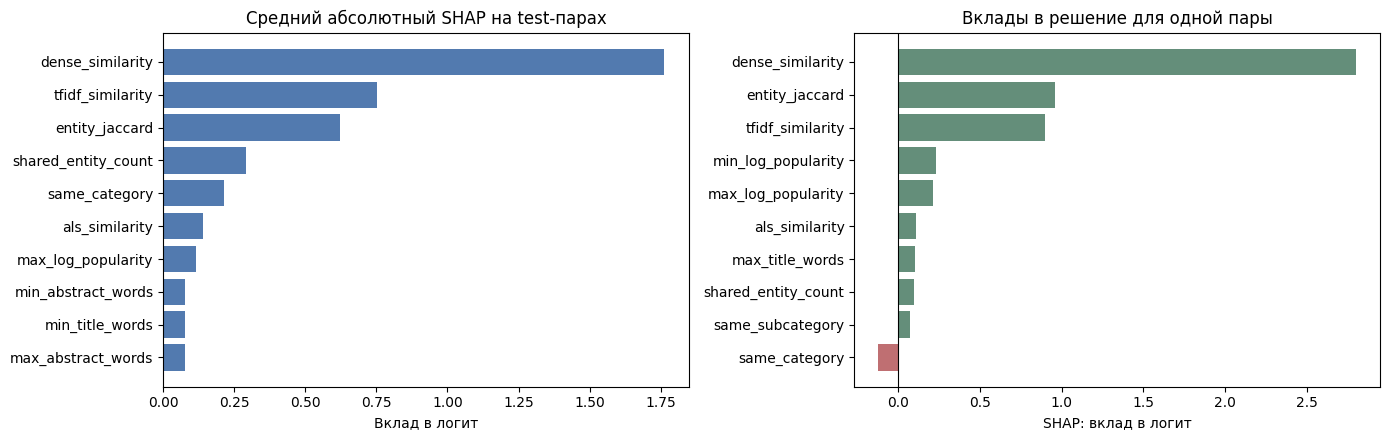

In [14]:
rel_shap_pairs = scored_test_pairs.sample(n=min(256, scored_test_pairs.height), seed=SEED)
rel_shap_features = features.frame([features.index[item] for item in rel_shap_pairs['anchor_id']], [features.index[item] for item in rel_shap_pairs['candidate_id']])
rel_shap = shap_contributions(model, rel_shap_features)
rel_logits = model.predict(rel_shap_features.to_numpy(), prediction_type='RawFormulaVal')
np.testing.assert_allclose(rel_shap['base_value'] + rel_shap['values'].sum(axis=1), rel_logits, atol=1e-08)
example_index = int(np.argmax(rel_shap_pairs['relevance_score'].to_numpy()))
local_rel = pl.DataFrame({'feature': rel_shap_features.columns, 'value': rel_shap_features.row(example_index), 'shap': rel_shap['values'][example_index]}).with_columns(pl.col('shap').abs().alias('magnitude')).sort('magnitude', descending=True)
display(rel_shap['importance'].head(10))
display(local_rel.drop('magnitude').head(10))
example_pair = rel_shap_pairs.row(example_index, named=True)
print('Anchor:', news_for_examples[example_pair['anchor_id']]['title'])
print('Кандидат:', news_for_examples[example_pair['candidate_id']]['title'])
print(f"Базовый логит: {rel_shap['base_value'][example_index]:.3f}; сумма вкладов: {rel_shap['values'][example_index].sum():.3f}; score: {1 / (1 + np.exp(-rel_logits[example_index])):.3f}")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
global_rel = rel_shap['importance'].head(10).sort('mean_abs_shap')
axes[0].barh(global_rel['feature'], global_rel['mean_abs_shap'], color='#527aaf')
axes[0].set(title='Средний абсолютный SHAP на test-парах', xlabel='Вклад в логит')
shown_local = local_rel.head(10).sort('shap')
axes[1].barh(shown_local['feature'], shown_local['shap'], color=['#648e7a' if x >= 0 else '#bf6f72' for x in shown_local['shap']])
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set(title='Вклады в решение для одной пары', xlabel='SHAP: вклад в логит')
fig.tight_layout()
plt.show()

## 4. Рабочий порог релевантности: 0.8

![Порог превращает непрерывный score в решение оставить или удалить пару](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/09_threshold.png)

**Вход:** r(A,i) и фиксированный порог τ. **Выход:** бинарное решение
$\widehat y_{Ai}=1[r(A,i)\ge\tau]$.
Главная цель — отсечь нерелевантные пары; рабочий **τ=0.8**.

$$
Precision=\frac{TP}{TP+FP},\qquad Recall=\frac{TP}{TP+FN},\qquad
Specificity=\frac{TN}{TN+FP},\qquad F_1=\frac{2PR}{P+R}.
$$

TP/FP — оставленные релевантные/нерелевантные; FN/TN — удалённые релевантные/нерелевантные.
На размеченном test при 0.8: TP=84, FP=12, FN=200, TN=1700.
Получаем precision 87.5%, recall 29.6%, specificity 99.3%.
При 0.7 specificity 98.6%, precision 81.5%, recall 37.3%.
Низкий recall — принятая цена строгого фильтра; это метрики размеченного пула пар.

ROC-AUC оценивает порядок по непрерывным scores:

$$
AUC=\Pr(r^+>r^-)+\tfrac12\Pr(r^+=r^-).
$$

Здесь $r^+$ и $r^-$ — scores случайных положительной и отрицательной пар.
Порог в определение не входит. PR-AUC в коде — **average precision**:
$AP=\sum_k(Recall_k-Recall_{k-1})Precision_k$ по различным уровням score.
На test ROC-AUC=0.9105, AP=0.6858.

Максимум F1 на validation оставляем для сравнения: он отвечает другому приоритету, балансу precision/recall.
Численный score не объявляем калиброванной вероятностью и не трактуем 0.8 как гарантию precision 80%.


threshold,selection,feasible,kept,precision,recall,f1
f64,str,bool,i64,f64,f64,f64
0.8,"""fixed""",true,112,0.866071,0.322259,0.469734


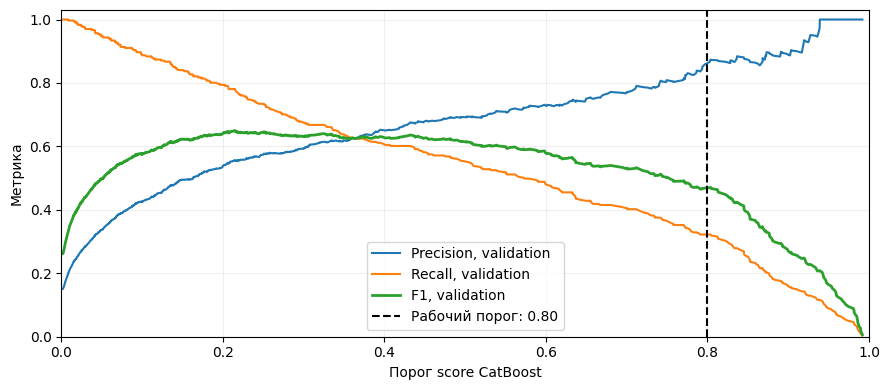

threshold,precision,recall,negative_rejection,false_positive,false_negative
f64,f64,f64,f64,i64,i64
0.215227,0.556872,0.780731,0.889935,187,66
0.7,0.772152,0.405316,0.978811,36,179
0.8,0.866071,0.322259,0.991171,15,204


In [15]:
TAU = classification['threshold']['threshold']
display(pl.DataFrame([classification['threshold']]))
curve = pl.read_parquet(ARTIFACTS / 'validation_thresholds.parquet').sort('threshold')
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(curve['threshold'], curve['precision'], label='Precision, validation')
ax.plot(curve['threshold'], curve['recall'], label='Recall, validation')
ax.plot(curve['threshold'], curve['f1'], label='F1, validation', linewidth=2)
ax.axvline(TAU, color='black', linestyle='--', label=f'Рабочий порог: {TAU:.2f}')
ax.set(xlabel='Порог score CatBoost', ylabel='Метрика', ylim=(0, 1.03), xlim=(0, 1))
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(ARTIFACTS / 'validation_tradeoff.png', dpi=150)
plt.show()
predictions = pl.read_parquet(ARTIFACTS / 'labelled_predictions.parquet')
valid = predictions.filter(pl.col('split') == 'validation')
f1_threshold = operating_threshold(valid['relevant'], valid['relevance_score'])['threshold']
policy_rows = []
for value in sorted({0.7, 0.8, f1_threshold}):
    metrics = classification_metrics(valid['relevant'], valid['relevance_score'], value)
    metrics['negative_rejection'] = metrics['true_negative'] / (metrics['true_negative'] + metrics['false_positive'])
    policy_rows.append({'threshold': value, **metrics})
display(pl.DataFrame(policy_rows).select('threshold', 'precision', 'recall', 'negative_rejection', 'false_positive', 'false_negative'))

## 5. Общие FAISS-индексы

![Для трёх массивов каталога строятся общие HNSW-индексы с исходными ID](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/10_faiss.png)

**Вход:** нормированные каталоговые векторы. **Выход:** по одному общему HNSW-индексу на пространство.
Во всех пространствах сохраняем общие ID объектов, даже если часть векторов не индексируется.

Поиск в пространстве m приближает множество лучших K соседей:

$$
KNN_m(A)\approx\operatorname{TopK}_{i\inI_m,\ i\ne A}\ z_m(A)^\top z_m(i),\qquad K=100.
$$

HNSW ищет по графу соседей вместо полного сравнения со всем каталогом. Это приближённый top-K,
поэтому найденные соседи могут отличаться от точного поиска.
Из результатов удаляем сам anchor и некорректные записи; возвращаем до K кандидатов. Для нулевого query выдача пуста.

Индекс не создаётся заново для каждой новости или пользователя.
Объект истории — запрос к общей структуре, а полученная выдача — отдельный i2i-список кандидатов.


In [16]:
EDGE_SCHEMA = {'anchor_index': pl.Int64, 'candidate_index': pl.Int64, 'source': pl.String, 'rank': pl.Int64, 'index_score': pl.Float64}

def build_index(vectors, hnsw_m=24):
    values, valid = normalize_rows(vectors)
    faiss.omp_set_num_threads(4)
    hnsw = faiss.IndexHNSWFlat(values.shape[1], hnsw_m, faiss.METRIC_INNER_PRODUCT)
    hnsw.hnsw.efConstruction = 100
    hnsw.hnsw.efSearch = 128
    index = faiss.IndexIDMap2(hnsw)
    index.add_with_ids(np.ascontiguousarray(values[valid]), np.flatnonzero(valid).astype(np.int64))
    return index

def prepare_indices(vectors, output_dir):
    faiss.omp_set_num_threads(4)
    output_dir = Path(output_dir)
    indices, summary = ({}, [])
    for name, matrix in vectors.items():
        fingerprint = hashlib.sha256(np.ascontiguousarray(matrix).tobytes()).hexdigest()
        path, meta_path = (output_dir / f'{name}.faiss', output_dir / f'{name}_index.json')
        settings = dict(vectors_sha256=fingerprint, hnsw_m=24, ef_construction=100, ef_search=128, faiss_version=faiss.__version__)
        previous = json.loads(meta_path.read_text()) if meta_path.exists() else {}
        if path.exists() and previous.get('settings') == settings:
            index = faiss.read_index(str(path))
            build_seconds = previous['build_seconds']
        else:
            started = perf_counter()
            index = build_index(matrix)
            build_seconds = perf_counter() - started
            faiss.write_index(index, str(path))
            meta_path.write_text(json.dumps(dict(settings=settings, build_seconds=build_seconds), indent=2))
        indices[name] = index
        summary.append(dict(source=name, dimensions=matrix.shape[1], indexed_items=index.ntotal, catalog_items=len(matrix), build_seconds=build_seconds, bytes=path.stat().st_size))
    table = pl.DataFrame(summary)
    table.write_csv(output_dir / 'indices.csv')
    return (indices, table)

def search_index(index, vectors, query_indices, k=100, source='dense'):
    if k < 1:
        raise ValueError('k must be positive')
    query_indices = np.asarray(query_indices, dtype=np.int64)
    queries, valid = normalize_rows(vectors[query_indices])
    if not valid.any() or not index.ntotal:
        return pl.DataFrame(schema=EDGE_SCHEMA)
    scores, ids = index.search(np.ascontiguousarray(queries[valid]), min(k + 1, index.ntotal))
    result = []
    for anchor, distances, neighbors in zip(query_indices[valid], scores, ids):
        rank = 0
        for score, candidate in zip(distances, neighbors):
            if candidate < 0 or candidate == anchor or (not np.isfinite(score)):
                continue
            rank += 1
            if rank > k:
                break
            result.append(dict(anchor_index=int(anchor), candidate_index=int(candidate), source=source, rank=rank, index_score=float(score)))
    return pl.DataFrame(result, schema=EDGE_SCHEMA)

def retrieve_candidates(indices, vectors, anchor_indices, k=100):
    return pl.concat([search_index(indices[name], matrix, anchor_indices, k, name) for name, matrix in vectors.items()])

def union_candidates(edges):
    return edges.group_by('anchor_index', 'candidate_index').agg(pl.col('source').unique().sort().alias('sources'), pl.col('source').n_unique().alias('n_sources'), pl.col('rank').min().alias('best_source_rank')).sort('anchor_index', 'candidate_index')

def score_candidates(union, features, model):
    matrix = features.frame(union['anchor_index'].to_numpy(), union['candidate_index'].to_numpy())
    scores = model.predict_proba(matrix.to_numpy())[:, 1] if union.height else np.array([], dtype=float)
    return union.with_columns(pl.Series('relevance_score', scores))

In [17]:
indices, index_summary = prepare_indices(vectors, ARTIFACTS)
display(index_summary.with_columns((pl.col('bytes') / 2 ** 20).round(2).alias('size_MiB')).drop('bytes'))

source,dimensions,indexed_items,catalog_items,build_seconds,size_MiB
str,i64,i64,i64,f64,f64
"""dense""",384,50451,50451,21.51305,84.31
"""lexical""",128,50451,50451,6.807387,35.04
"""als""",64,39408,50451,3.785843,17.75


## 6. Выбор позитивов пользователя

![Выбираем пользователей и h различных позитивов каждого](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/11_anchors.png)

Пусть $h$ — число позитивов, которые используем для одного пользователя.
Выбираем пользователей с достаточно длинной историей:

$$
U_{eligible}=\{u:|H(u)|\ge h\}.
$$

Из истории каждого выбранного пользователя случайно берём h различных объектов.
Получаем подмножество:

$$
H_h(u)\subseteq H(u),\qquad |H_h(u)|=h.
$$

Для всех выбранных пользователей собираем общий набор уникальных anchors:

$$
S=\bigcup_{u\in U_{sample}}H_h(u).
$$

Списки строим один раз для каждого объекта из S, затем переиспользуем у пользователей с общими anchors.

В демонстрации выбираем 50 пользователей и h=10 позитивов на пользователя.
Это 500 позиций истории и 461 уникальный anchor.
Отбор случайный, поэтому порядок выбранных anchors не обозначает давность.
Это статическая эмуляция на обучающем снимке; временную оценку будущих кликов рассматриваем отдельно.


In [18]:
USER_SCHEMA = {'user_id': pl.String, 'candidate_index': pl.Int64, 'best_anchor_index': pl.Int64, 'relevance_score': pl.Float64, 'supporting_anchors': pl.List(pl.Int64), 'support_count': pl.Int64, 'display_rank': pl.Int64}

def sample_user_anchors(user_item, user_ids, count=50, history_size=10, seed=42):
    rng = np.random.default_rng(seed)
    eligible = np.flatnonzero(np.diff(user_item.indptr) >= history_size)
    if count > len(eligible) or history_size < 1:
        raise ValueError('Not enough users with the requested number of distinct positives')
    result = []
    for user_index in sorted(rng.choice(eligible, size=count, replace=False)):
        history = user_item.indices[user_item.indptr[user_index]:user_item.indptr[user_index + 1]]
        for position, anchor in enumerate(rng.choice(history, size=history_size, replace=False)):
            result.append(dict(user_id=user_ids[user_index], user_index=int(user_index), anchor_index=int(anchor), anchor_no=position))
    return pl.DataFrame(result)

def user_candidates(sample, scored, user_item, threshold):
    by_anchor = defaultdict(list)
    for row in scored.filter(pl.col('relevance_score') >= threshold).select('anchor_index', 'candidate_index', 'relevance_score').iter_rows(named=True):
        by_anchor[row['anchor_index']].append(row)
    result = []
    for _, history in sample.group_by('user_id', maintain_order=True):
        user_id, user_index = (history['user_id'][0], history['user_index'][0])
        seen = set(user_item.indices[user_item.indptr[user_index]:user_item.indptr[user_index + 1]])
        candidates = {}
        for anchor in history['anchor_index']:
            for row in by_anchor[anchor]:
                candidate, score = (row['candidate_index'], row['relevance_score'])
                if candidate in seen:
                    continue
                if candidate not in candidates:
                    candidates[candidate] = dict(best=anchor, score=score, support=set())
                evidence = candidates[candidate]
                evidence['support'].add(anchor)
                if (score, -anchor) > (evidence['score'], -evidence['best']):
                    evidence.update(best=anchor, score=score)
        ordered = sorted(candidates.items(), key=lambda item: (-item[1]['score'], item[0]))
        for rank, (candidate, evidence) in enumerate(ordered, 1):
            result.append(dict(user_id=user_id, candidate_index=candidate, best_anchor_index=evidence['best'], relevance_score=evidence['score'], supporting_anchors=sorted(evidence['support']), support_count=len(evidence['support']), display_rank=rank))
    return pl.DataFrame(result, schema=USER_SCHEMA)

def threshold_statistics(scored, sample, user_item, thresholds):
    anchors = sample['anchor_index'].unique().to_list()
    users = sample['user_id'].n_unique()
    rows = []
    for threshold in sorted(set((float(value) for value in thresholds))):
        kept = scored.filter(pl.col('relevance_score') >= threshold)
        lengths = dict(kept.group_by('anchor_index').len().iter_rows())
        sizes = np.array([lengths.get(anchor, 0) for anchor in anchors])
        combined = user_candidates(sample, scored, user_item, threshold)
        used_history = sum((len({anchor for support in group['supporting_anchors'] for anchor in support}) for _, group in combined.group_by('user_id')))
        rows.append(dict(threshold=threshold, pairs_before=scored.height, pairs_after=kept.height, retained_fraction=kept.height / max(1, scored.height), mean_anchor_length=float(sizes.mean()), median_anchor_length=float(np.median(sizes)), nonempty_anchors=int((sizes > 0).sum()), anchor_coverage=float((sizes > 0).mean()), user_candidates=combined.height, nonempty_users=combined['user_id'].n_unique(), mean_user_candidates=combined.height / max(1, users), history_coverage_after_seen_filter=used_history / sample.height))
    return pl.DataFrame(rows)

def with_news_ids(frame, rows):
    mapping = [r['news_id'] for r in rows]
    expressions = []
    for column, target in [('anchor_index', 'anchor_id'), ('candidate_index', 'candidate_id'), ('best_anchor_index', 'best_anchor_id')]:
        if column in frame.columns:
            expressions.append(pl.col(column).map_elements(lambda i: mapping[i], return_dtype=pl.String).alias(target))
    return frame.with_columns(expressions)

In [19]:
sample = sample_user_anchors(resources.user_item, resources.user_ids, count=USER_COUNT, history_size=HISTORY_SIZE, seed=SEED)
anchor_indices = np.sort(sample['anchor_index'].unique().to_numpy())
catalog = pl.DataFrame(resources.rows).with_row_index('catalog_index')
first_user = sample['user_id'][0]
display(sample.filter(pl.col('user_id') == first_user).join(catalog.select(pl.col('catalog_index').cast(pl.Int64).alias('anchor_index'), 'news_id', 'title', 'category'), on='anchor_index').select('user_id', 'anchor_no', 'news_id', 'category', 'title'))
print(f"Пользователей: {sample['user_id'].n_unique()}; запросов из истории: {sample.height}; уникальных anchors: {len(anchor_indices)}")

user_id,anchor_no,news_id,category,title
str,i64,str,str,str
"""U15210""",3,"""N1034""","""news""","""'Baby Trump' balloon slashed at Alabama appearance"""
"""U15210""",2,"""N16715""","""news""","""Mitch McConnell snubbed by Elijah Cummings' pallbearer in handsh…"
"""U15210""",8,"""N20710""","""travel""","""A former Nazi bunker in Germany is being turned into a luxury ho…"
"""U15210""",1,"""N3926""","""lifestyle""","""Duchess of Cambridge enthuses over 'fantastic' Pakistan in rare …"
"""U15210""",5,"""N49048""","""lifestyle""","""How to Adopt a Retired Police Dog"""
"""U15210""",0,"""N52555""","""lifestyle""","""Man Goes To Adoption Event And Finds His Long-Lost Dog"""
"""U15210""",6,"""N6616""","""news""","""Felicity Huffman Smiles as She Begins Community Service Followin…"
"""U15210""",4,"""N7432""","""video""","""The World's Largest Desert Is Covered In Ice"""
"""U15210""",7,"""N8258""","""news""","""New Hampshire Couple's Adventure Ends in Mysterious Death in Tex…"


Пользователей: 50; запросов из истории: 500; уникальных anchors: 461


## 7. Отдельные источники → union

![Dense, lexical и ALS выдают до 100 соседей; union сохраняет один candidate и все источники](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/12_union.png)

**Вход:** три выдачи для одного anchor. **Выход:** уникальные пары (A,i) и происхождение каждого кандидата.

$$
C(A)=KNN_{dense}(A)\cup KNN_{lexical}(A)\cup KNN_{als}(A),
\qquad Sources(A,i)=\{m:i\in KNN_m(A)\}.
$$

Верхняя граница — $|C(A)|\le\sum_m|KNN_m(A)|\le300$.
Повторы источников уменьшают фактический union. Ключ дедупликации — **(anchor, candidate)**:
один candidate может законно находиться в списках разных anchors.
Сохраняем происхождение кандидата: какие источники его нашли и на какие позиции поставили.

В запуске: 138300 рёбер источников → 127214 уникальных пар.
Сходства разных пространств служат диагностикой поиска; здесь их не складываем в единый score.
Следующий этап считает общие признаки и применяет CatBoost.


In [20]:
edges = retrieve_candidates(indices, vectors, anchor_indices, k=K_PER_SOURCE)
union = union_candidates(edges)
display(edges.group_by('source').agg(pl.len().alias('edges'), pl.col('anchor_index').n_unique().alias('anchors')))
display(union.group_by('n_sources').len().sort('n_sources'))
print(f'Рёбер до объединения: {edges.height:,}; различных пар: {union.height:,}')

source,edges,anchors
str,u32,u32
"""dense""",46100,461
"""lexical""",46100,461
"""als""",46100,461


n_sources,len
u32,u32
1,116873
2,9617
3,731


Рёбер до объединения: 138,300; различных пар: 127,221


## 8. Скоринг и фильтрация

![Каждая пара union получает score обученного классификатора и проходит порог 0.8](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/13_filter.png)

**Вход:** union C(A). Считаем те же 17 признаков, что при обучении,
и получаем оценку модели релевантности. **Выход:**

$$
F_\tau(A)=\{i\in C(A):r(A,i)\ge\tau\},\qquad \tau=0.8.
$$

Критерий применяется к **выходу CatBoost**, а не к cosine FAISS.
Если для anchor не осталось пар, его список пуст; искусственного дополнения нет.
При $\tau_2\ge\tau_1$ множества вложены:

$$
F_{\tau_2}(A)\subseteq F_{\tau_1}(A)\subseteq C(A).
$$

На текущем запуске 127214 пар union сокращаются до 4633.
Общие FAISS-индексы остаются исходными: сокращается набор сохраняемых i2i-пар.
В следующем шаге аттрактивность изменит только порядок этих пар.


In [21]:
scored = score_candidates(union, features, model)
filtered = scored.filter(pl.col('relevance_score') >= TAU)
print(f'Пар до порога: {scored.height:,}; после: {filtered.height:,}; осталось: {filtered.height / scored.height:.2%}')
display(scored.explode('sources').group_by('sources').agg(pl.len().alias('candidates'), (pl.col('relevance_score') >= TAU).sum().alias('kept')).sort('sources'))

Пар до порога: 127,221; после: 4,688; осталось: 3.68%


sources,candidates,kept
str,u32,u32
"""als""",46100,555
"""dense""",46100,4287
"""lexical""",46100,2829


In [22]:
def show_pairs(frame):
    described = with_news_ids(frame, resources.rows).join(catalog.select(pl.col('news_id').alias('anchor_id'), pl.col('title').alias('anchor_title')), on='anchor_id').join(catalog.select(pl.col('news_id').alias('candidate_id'), pl.col('title').alias('candidate_title')), on='candidate_id')
    return described.select('anchor_title', 'candidate_title', 'relevance_score', 'sources')
if filtered.is_empty():
    print('При выбранном пороге непустых списков нет.')
else:
    example_anchor = filtered.group_by('anchor_index').len().sort('len', descending=True)['anchor_index'][0]
    display(show_pairs(scored.filter(pl.col('anchor_index') == example_anchor).sort('relevance_score', descending=True).head(12)))

anchor_title,candidate_title,relevance_score,sources
str,str,f64,list[str]
"""World Series Game 2 Highlights: Nationals vs. Astros""","""World Series Open Thread: Nationals vs. Astros""",0.989629,"[""dense""]"
"""World Series Game 2 Highlights: Nationals vs. Astros""","""Washington Nationals' lineup for Game 7 of the World Series with…",0.975222,"[""dense"", ""lexical""]"
"""World Series Game 2 Highlights: Nationals vs. Astros""","""NLCS Game 4: Nationals complete sweep to clinch first-ever World…",0.97585,"[""dense"", ""lexical""]"
"""World Series Game 2 Highlights: Nationals vs. Astros""","""World Series: How the Nationals and Astros match up""",0.97816,"[""dense"", ""lexical""]"
"""World Series Game 2 Highlights: Nationals vs. Astros""","""Wire Taps: Washington Nationals trounce Houston Astros, take 2-0…",0.975143,"[""dense"", ""lexical""]"
"""World Series Game 2 Highlights: Nationals vs. Astros""","""Astros enter World Series against Nationals as heaviest favorite…",0.972637,"[""dense"", ""lexical""]"
"""World Series Game 2 Highlights: Nationals vs. Astros""","""Nationals Vs. Astros, World Series Game 2: What You Need To Know""",0.97857,"[""dense""]"
"""World Series Game 2 Highlights: Nationals vs. Astros""","""Winners, losers from the Nationals' dominating Game 2 win""",0.988079,"[""dense"", ""lexical""]"
"""World Series Game 2 Highlights: Nationals vs. Astros""","""MLB world reacts to Astros' seventh-inning collapse in Game 2 of…",0.989449,"[""dense"", ""lexical""]"


## 9. Модель аттрактивности

![Anchor берётся из истории до показа; предпочтения формируются между показанными clicked и unclicked](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/14_logged_pairs.png)

**Вход:** один показ e пользователя u и его история **до** этого показа.
Выбираем до двух anchors из истории и формируем отдельную группу $g=(e,A)$ для каждого.
Из показанных новостей берём до трёх clicked и пяти unclicked.
Канонические дубли объединяем; уже прочитанные candidates и самопары исключаем.
**Выход:** кандидаты с результатами взаимодействия и пары предпочтения для одного anchor.

В лекции target — время просмотра: для B,C,D это 300,60,0 секунд.
Пары: B>C с весом 240, B>D с весом 300, C>D с весом 60.
Общее правило:

$$
P_g=\{(w,l):w,l\in g,\ y_w>y_l\},\qquad \omega_{wl}=y_w-y_l.
$$

В MIND времени чтения нет: используем $y_i=click_i\in\{0,1\}$.
Winner — clicked, loser — **показанный** unclicked, $\omega_{wl}=1$.
Непоказанные объекты не образуют negatives; равные targets не образуют предпочтений.

Для $n_+$ clicked и $n_-$ unclicked в группе получается $n_+n_-$ пар.
Одна clicked и пять unclicked дают пять пар, хотя строк модели шесть.
Показ без клика — слабое наблюдение предпочтения, а не доказанная тематическая нерелевантность.
ID пользователя/показа нужны для сборки групп, но в признаки модели не входят.


### 9.1. Поведенческий снимок и направленные признаки

![Сначала фиксируем признаки, затем выделяем периоды обучения и оценки](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/15_time.png)

Поведенческий снимок фиксируем **до 10 ноября 2019**. Из более ранних строк считаем
аудиторию, показы, клики и отдельно обучаем ALS64.
Retrieval ALS обучен на всём train; его более поздние взаимодействия нельзя использовать
для честной оценки будущих кликов, поэтому у ранжировщика свой ALS и своя аудитория.
Тексты/TF-IDF берём из фиксированного каталога; доступность новостей во времени не моделируется.

Train — показы 10–12 ноября, validation — 13 ноября, test — 14 ноября.
Все группы одного показа целиком находятся в одной части.
Два anchors одного показа дают зависимые примеры; статистическую значимость здесь не оцениваем.

Вход ранжировщика — 17 парных признаков на раннем снимке и пять направленных:
популярность anchor/candidate, число показов/кликов candidate и сглаженный CTR.
Для кандидата i:

$$
CTR_{prior}=\frac{\sum_j clicks_j}{\sum_j shows_j},\qquad
\widetilde{CTR}_i=\frac{clicks_i+20\,CTR_{prior}}{shows_i+20}.
$$

Счётчики преобразуются через $\log(1+x)$. Все величины справа считаются только до cutoff.
Пять направленных признаков различают роли A и i, поэтому $\phi_{attr}(A,i)$ в общем случае
отличается от $\phi_{attr}(i,A)$, хотя первые 17 признаков симметричны.
Данных об издателе нет, поэтому этот тип сходства здесь не используем.

### 9.2. PairLogit: учим score winner больше score loser

![Одна модель считает два score; разность score входит в взвешенный pairwise-loss](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/16_pairlogit.png)

Применяем общую модель $s_\theta(A,i)$ к каждой строке пары. Для winner w и loser l:

$$
\Delta s_{Awl}=s_\theta(A,w)-s_\theta(A,l),\qquad
L_{attr}=\sum_g\sum_{(w,l)\inP_g}
\omega_{wl}\log(1+e^{-\Delta s_{Awl}}).
$$

Если winner уже выше loser, увеличение разницы уменьшает loss.
При обратном порядке модель получает больший штраф. Target задаёт **относительное предпочтение**,
а абсолютный score остаётся произвольным. В PairLogit $\sigma(\Delta s)$ задаёт модельное парное предпочтение;
$s$ не является вероятностью клика отдельного документа.

Сравниваем только кандидатов одного показа при фиксированном anchor.
Качество порядка контролируем на validation, а итоговую оценку получаем на отложенных показах.

При применении loser не нужен: для каждого кандидата отдельно считаем s(A,i), затем сортируем.
Добавление константы ко всем scores одного anchor не меняет pairwise-loss,
поэтому прямое сравнение абсолютных scores разных anchors не обосновано этим обучением.

### 9.3. Метрики ранжирования

![На одинаковых logged subsets сравниваем ранжировщик и baseline через NDCG, MRR и pair accuracy](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/17_rank_metrics.png)

Оцениваем модель и baselines на **одних и тех же показанных кандидатах до relevance-фильтра**.
Это проверяет функцию предпочтения; uplift в итоговом FAISS-пуле и будущий CTR так не измеряются.
Пусть $\pi_g$ — порядок группы g по score; target бинарный. Тогда:

$$
DCG@k(g)=\sum_{j=1}^{\min(k,|g|)}\frac{y_{\pi_g(j)}}{\log_2(j+1)},\qquad
NDCG@k(g)=\frac{DCG@k(g)}{IDCG@k(g)}.
$$

IDCG — DCG идеального порядка. В группах есть хотя бы один click.
Считаем NDCG@10; при семплировании до 8 объектов это оценка порядка всей группы.
Усредняем NDCG и reciprocal rank по группам:

$$
MRR=\frac1{|G|}\sum_{g\inG}\frac1{\min\{j:y_{\pi_g(j)}=1\}},\qquad
PairAcc=\frac{\sum_{g,(w,l)\inP_g}\omega_{wl}
\left(1[s_w>s_l]+\tfrac121[s_w=s_l]\right)}
{\sum_{g,(w,l)\inP_g}\omega_{wl}}.
$$

PairAcc учитывает веса; ничья получает половину веса. Для сортировки при равенстве используется ID кандидата.
Baselines: dense cosine, ранний ALS cosine и ранняя популярность candidate.
Абсолютные значения метрик зависят от размера набора сравниваемых кандидатов.


**Дополнительные признаки модели аттрактивности**

Ранкер использует все 17 признаков из таблицы модели релевантности и ещё пять направленных признаков:

| Признак | Как считается |
|---|---|
| `anchor_log_users` | $\log(1+\text{число уникальных пользователей с позитивом к anchor})$ |
| `candidate_log_users` | То же для кандидата |
| `candidate_log_exposures` | $\log(1+shows_i)$ — число появлений кандидата в показах |
| `candidate_log_clicks` | $\log(1+clicks_i)$ — число кликов по кандидату |
| `candidate_smoothed_ctr` | $(clicks_i+20\,CTR_{prior})/(shows_i+20)$ |

Итого — 22 признака. Все поведенческие признаки ранкера, включая общую аудиторию,
вычислены до 10 ноября. Повторы позитивов не увеличивают размер аудитории,
но повторные показы и клики учитываются как отдельные события.


In [23]:
CUTOFF = '2019-11-10T00:00:00'
GROUP_SCHEMA = dict(group_id=pl.Int64, impression_id=pl.String, timestamp=pl.String, split=pl.String, anchor_index=pl.Int64, candidate_index=pl.Int64, target=pl.Float64)
DIRECTIONAL_NAMES = ['anchor_log_users', 'candidate_log_users', 'candidate_log_exposures', 'candidate_log_clicks', 'candidate_smoothed_ctr']

def frozen_feedback(records, alias_index, catalog_size, cutoff=CUTOFF):
    histories = defaultdict(set)
    clicks, exposures = (np.zeros(catalog_size), np.zeros(catalog_size))
    for record in records:
        if record['timestamp'] >= cutoff:
            continue
        history = histories[record['user_id']]
        history.update((alias_index[item] for item in record['history'].split() if item in alias_index))
        for item, target in shown_items(record, alias_index).items():
            exposures[item] += 1
            clicks[item] += target
            if target:
                history.add(item)
    users, items = ([], [])
    for index, user in enumerate(sorted(histories)):
        values = sorted(histories[user])
        users.extend([index] * len(values))
        items.extend(values)
    matrix = csr_matrix((np.ones(len(items), dtype=np.float32), (users, items)), shape=(len(histories), catalog_size))
    return dict(user_item=matrix, clicks=clicks, exposures=exposures)

def preference_pairs(targets):
    pairs = []
    for i, left in enumerate(targets):
        for j in range(i + 1, len(targets)):
            right = targets[j]
            if left != right:
                winner, loser = (i, j) if left > right else (j, i)
                pairs.append((winner, loser, float(abs(left - right))))
    return pairs

def build_logged_groups(records, alias_index, max_impressions=None, anchors_per_impression=2, max_positive=3, max_negative=5, seed=42):
    limits = max_impressions or dict(train=8000, validation=2000, test=2000)
    rng = np.random.default_rng(seed)
    eligible = defaultdict(list)
    for record in records:
        time = record['timestamp']
        if time < CUTOFF:
            continue
        split = 'train' if time < '2019-11-13' else 'validation' if time < '2019-11-14' else 'test'
        history = sorted({alias_index[x] for x in record['history'].split() if x in alias_index})
        shown = shown_items(record, alias_index)
        positive = sorted((i for i, target in shown.items() if target == 1 and i not in history))
        negative = sorted((i for i, target in shown.items() if target == 0 and i not in history))
        if history and positive and negative:
            eligible[split].append((record, history, positive, negative))
    rows, group_id = ([], 0)
    for split in ['train', 'validation', 'test']:
        candidates = eligible[split]
        selected = rng.choice(len(candidates), min(len(candidates), limits.get(split, 0)), replace=False)
        for index in sorted(selected):
            record, history, positive, negative = candidates[index]
            positive = rng.choice(positive, min(len(positive), max_positive), replace=False).tolist()
            negative = rng.choice(negative, min(len(negative), max_negative), replace=False).tolist()
            anchors = rng.choice(history, min(len(history), anchors_per_impression), replace=False)
            for anchor in sorted(anchors):
                for candidate in sorted(positive + negative):
                    rows.append(dict(group_id=group_id, impression_id=record['impression_id'], timestamp=record['timestamp'], split=split, anchor_index=int(anchor), candidate_index=candidate, target=float(candidate in positive)))
                group_id += 1
    return pl.DataFrame(rows, schema=GROUP_SCHEMA)

class AttractivenessFeatures:

    def __init__(self, base, snapshot):
        self.base = base
        self.users = np.log1p(np.asarray(snapshot['user_item'].sum(axis=0)).ravel())
        self.exposures = snapshot['exposures']
        self.clicks = snapshot['clicks']
        self.prior = self.clicks.sum() / max(1, self.exposures.sum())

    def frame(self, anchors, candidates):
        a, b = (np.asarray(anchors, dtype=int), np.asarray(candidates, dtype=int))
        return self.base.frame(a, b).with_columns(pl.Series('anchor_log_users', self.users[a]), pl.Series('candidate_log_users', self.users[b]), pl.Series('candidate_log_exposures', np.log1p(self.exposures[b])), pl.Series('candidate_log_clicks', np.log1p(self.clicks[b])), pl.Series('candidate_smoothed_ctr', (self.clicks[b] + 20 * self.prior) / (self.exposures[b] + 20)))

def prepare_attractiveness_features(resources, records, alias_index, output_dir, seed=42):
    from implicit.als import AlternatingLeastSquares
    snapshot = frozen_feedback(records, alias_index, len(resources.rows))
    matrix = snapshot['user_item']
    fingerprint = hashlib.sha256(matrix.data.tobytes() + matrix.indices.tobytes() + matrix.indptr.tobytes()).hexdigest()
    settings = dict(cutoff=CUTOFF, feedback=fingerprint, factors=64, iterations=30, alpha=20, regularization=0.1, seed=seed)
    path = Path(output_dir)
    path.mkdir(parents=True, exist_ok=True)
    info_path = path / 'snapshot.json'
    old = json.loads(info_path.read_text()) if info_path.exists() else {}
    if old.get('settings') == settings and (path / 'als_vectors.npy').exists():
        factors = np.load(path / 'als_vectors.npy')
    else:
        with threadpool_limits(limits=1, user_api='blas'):
            als = AlternatingLeastSquares(factors=64, iterations=30, alpha=20, regularization=0.1, random_state=seed, num_threads=4, use_gpu=False)
            als.fit(matrix, show_progress=False)
        factors = normalize_rows(als.item_factors)[0]
        np.save(path / 'als_vectors.npy', factors)
    rows = [dict(row, click_count=int(snapshot['clicks'][i])) for i, row in enumerate(resources.rows)]
    base = PairFeatures(rows, resources.embeddings, resources.tfidf, matrix, item_factors=factors)
    info = dict(settings=settings, users=matrix.shape[0], interactions=matrix.nnz, clicks=int(snapshot['clicks'].sum()), exposures=int(snapshot['exposures'].sum()))
    info_path.write_text(json.dumps(info, indent=2) + '\n')
    return (AttractivenessFeatures(base, snapshot), info)

def pool_for_groups(frame, matrix):
    from catboost import Pool
    pairs, weights = ([], [])
    offset = 0
    for _, group in frame.group_by('group_id', maintain_order=True):
        for winner, loser, weight in preference_pairs(group['target'].to_list()):
            pairs.append((offset + winner, offset + loser))
            weights.append(weight)
        offset += group.height
    return (Pool(matrix.to_numpy(), label=frame['target'].to_numpy(), group_id=frame['group_id'].to_numpy(), pairs=pairs, pairs_weight=weights, feature_names=matrix.columns), len(pairs))

def ranking_metrics(frame, scores, k=10):
    values = frame.with_columns(pl.Series('_score', np.asarray(scores, dtype=float)))
    ndcg, reciprocal, correct, weight_sum = ([], [], 0.0, 0.0)
    for _, group in values.group_by('group_id', maintain_order=True):
        y, score = (group['target'].to_numpy(), group['_score'].to_numpy())
        order = np.argsort(-score, kind='stable')
        discount = 1 / np.log2(np.arange(min(k, len(y))) + 2)
        ideal = float(np.dot(np.sort(y)[::-1][:k], discount))
        ndcg.append(float(np.dot(y[order][:k], discount)) / ideal if ideal else 0.0)
        positions = np.flatnonzero(y[order] > 0)
        reciprocal.append(1 / (positions[0] + 1) if len(positions) else 0.0)
        for winner, loser, weight in preference_pairs(y):
            correct += weight * (1.0 if score[winner] > score[loser] else 0.5 if score[winner] == score[loser] else 0.0)
            weight_sum += weight
    return dict(groups=len(ndcg), rows=frame.height, ndcg_at_10=float(np.mean(ndcg)), mrr=float(np.mean(reciprocal)), pair_accuracy=correct / max(1, weight_sum))

def rerank_lists(filtered, scores):
    frame = filtered.sort(['anchor_index', 'relevance_score', 'candidate_index'], descending=[False, True, False]).with_columns(pl.int_range(1, pl.len() + 1).over('anchor_index').alias('relevance_rank'))
    scored = filtered.select('anchor_index', 'candidate_index').with_columns(pl.Series('attractiveness_score', scores))
    return frame.join(scored, on=['anchor_index', 'candidate_index'], how='left').sort(['anchor_index', 'attractiveness_score', 'candidate_index'], descending=[False, True, False]).with_columns(pl.int_range(1, pl.len() + 1).over('anchor_index').alias('attractiveness_rank'))

In [24]:
lecture_pairs = preference_pairs([300, 60, 0])
display(pl.DataFrame([{'winner': ['B', 'C', 'D'][w], 'loser': ['B', 'C', 'D'][l], 'weight': weight} for w, l, weight in lecture_pairs]))
logged_groups = build_logged_groups(behaviors_eda, alias_index_eda, seed=SEED)
rank_output = ARTIFACTS / 'attractiveness'
rank_output.mkdir(parents=True, exist_ok=True)
rank_features, rank_snapshot = prepare_attractiveness_features(resources, behaviors_eda, alias_index_eda, rank_output, seed=SEED)
rank_frames, rank_matrices, rank_pools, pair_counts = ({}, {}, {}, {})
for part in ['train', 'validation', 'test']:
    group_frame = logged_groups.filter(pl.col('split') == part).sort('group_id', 'candidate_index')
    matrix = rank_features.frame(group_frame['anchor_index'], group_frame['candidate_index'])
    rank_frames[part], rank_matrices[part] = (group_frame, matrix)
    rank_pools[part], pair_counts[part] = pool_for_groups(group_frame, matrix)
from catboost import CatBoostRanker
ranking_model = CatBoostRanker(iterations=600, depth=6, learning_rate=0.05, loss_function='PairLogit', eval_metric='NDCG:top=10', l2_leaf_reg=5, random_seed=SEED, thread_count=4, allow_writing_files=False)
ranking_model.fit(rank_pools['train'], eval_set=rank_pools['validation'], early_stopping_rounds=60, verbose=False)
rank_metrics, rank_predictions = ([], [])
for part, frame in rank_frames.items():
    values = ranking_model.predict(rank_pools[part])
    rank_predictions.append(frame.with_columns(pl.Series('attractiveness_score', values)))
    for name, scores in {'catboost_pairlogit': values, 'dense_similarity': rank_matrices[part]['dense_similarity'].to_numpy(), 'als_similarity': rank_matrices[part]['als_similarity'].to_numpy(), 'popularity': rank_matrices[part]['candidate_log_users'].to_numpy()}.items():
        rank_metrics.append({'split': part, 'model': name, **ranking_metrics(frame, scores)})
rank_report = {'pairs': pair_counts, 'metrics': rank_metrics, 'settings': {'cutoff': CUTOFF, 'snapshot': rank_snapshot}, 'tree_count': ranking_model.tree_count_}
ranking_model.save_model(str(rank_output / 'attractiveness_model.cbm'))
(rank_output / 'ranking_report.json').write_text(json.dumps(rank_report, indent=2))
logged_groups.write_parquet(rank_output / 'logged_groups.parquet')
pl.concat(rank_predictions).write_parquet(rank_output / 'logged_predictions.parquet')
pl.DataFrame(rank_metrics).write_csv(rank_output / 'ranking_metrics.csv')
pl.DataFrame({'feature': ranking_model.feature_names_, 'importance': ranking_model.get_feature_importance(rank_pools['train'])}).sort('importance', descending=True).write_csv(rank_output / 'feature_importance.csv')
ranked = rerank_lists(filtered, ranking_model.predict(rank_features.frame(filtered['anchor_index'], filtered['candidate_index']).to_numpy()))
attractiveness = {'model': ranking_model, 'report': rank_report, 'features': rank_features, 'groups': logged_groups, 'ranked': ranked}
display(logged_groups.group_by('split').agg(pl.col('impression_id').n_unique().alias('impressions'), pl.col('group_id').n_unique().alias('groups'), pl.len().alias('rows')).sort('split'))
first_group = logged_groups['group_id'][0]
display(with_news_ids(logged_groups.filter(pl.col('group_id') == first_group), resources.rows).join(catalog.select(pl.col('news_id').alias('candidate_id'), 'title'), on='candidate_id').select('impression_id', 'anchor_id', 'candidate_id', 'target', 'title'))

winner,loser,weight
str,str,f64
"""B""","""C""",240.0
"""B""","""D""",300.0
"""C""","""D""",60.0


split,impressions,groups,rows
str,u32,u32,u32
"""test""",2000,3978,24329
"""train""",8000,15891,92927
"""validation""",2000,3974,23832


impression_id,anchor_id,candidate_id,target,title
str,str,str,f64,str
"""1""","""N42782""","""N35729""",0.0,"""Porsche launches into second story of New Jersey building, killi…"
"""1""","""N42782""","""N55689""",1.0,"""Charles Rogers, former Michigan State football, Detroit Lions st…"


In [25]:
rank_report = attractiveness['report']
print('Пар предпочтения:', rank_report['pairs'])
ranking_metrics_table = pl.DataFrame(rank_report['metrics'])
display(ranking_metrics_table.filter(pl.col('split').is_in(['validation', 'test'])).select('split', 'model', 'groups', 'ndcg_at_10', 'mrr', 'pair_accuracy'))
rank_features = attractiveness['features']
small_group = logged_groups.filter(pl.col('group_id') == first_group)
display(rank_features.frame(small_group['anchor_index'], small_group['candidate_index']))
display(pl.read_csv(ARTIFACTS / 'attractiveness' / 'feature_importance.csv').head(10))

Пар предпочтения: {'train': 101182, 'validation': 26080, 'test': 26781}


split,model,groups,ndcg_at_10,mrr,pair_accuracy
str,str,i64,f64,f64,f64
"""validation""","""catboost_pairlogit""",3974,0.650762,0.546242,0.565548
"""validation""","""dense_similarity""",3974,0.638141,0.530209,0.549271
"""validation""","""als_similarity""",3974,0.596433,0.466377,0.485947
"""validation""","""popularity""",3974,0.591489,0.459407,0.477301
"""test""","""catboost_pairlogit""",3978,0.65507,0.55106,0.588701
"""test""","""dense_similarity""",3978,0.64075,0.530987,0.563945
"""test""","""als_similarity""",3978,0.596771,0.468917,0.494548
"""test""","""popularity""",3978,0.586277,0.455509,0.479575


dense_similarity,tfidf_similarity,als_similarity,collaborative_similarity,log_shared_users,same_category,…,max_log_popularity,anchor_log_users,candidate_log_users,candidate_log_exposures,candidate_log_clicks,candidate_smoothed_ctr
f64,f64,f64,f64,f64,f64,…,f64,f32,f32,f64,f64,f64
0.164422,0.0,0.0,0.0,0.0,0.0,…,0.0,3.78419,0.0,0.0,0.0,0.038524
0.114353,0.0,0.0,0.0,0.0,1.0,…,0.0,3.78419,0.0,0.0,0.0,0.038524


feature,importance
str,f64
"""candidate_smoothed_ctr""",0.008515
"""dense_similarity""",0.006586
"""max_abstract_words""",0.003537
"""same_subcategory""",0.002513
"""min_abstract_words""",0.001574
"""min_title_words""",0.000828
"""abstract_count""",0.000823
"""same_category""",0.000739
"""tfidf_similarity""",0.000413


### 9.4. Что влияет на порядок кандидатов?

![Важность признаков ранкера и разность SHAP-вкладов для clicked и unclicked одного показа](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/27_attractiveness_shap.png)

Сначала посмотрим важности признаков ранкера на обучающих группах и средние абсолютные SHAP-вклады на отложенных примерах.
Затем сравним кликнутого и некликнутого кандидата из одной группы:

$$
s(A,i)=b+\sum_j\phi_j(A,i),\qquad
s(A,w)-s(A,l)=\sum_j\left(\phi_j(A,w)-\phi_j(A,l)\right).
$$

Базовый уровень сокращается. Положительная разность вклада ставит кликнутый объект выше,
отрицательная поддерживает другой порядок. Так можно увидеть, что сработало для конкретного выбора:
содержательная близость, популярность или исторический CTR.
Если итоговая разность отрицательна, модель предпочла некликнутый объект — это пример ошибки ранжирования.


feature,mean_abs_shap
str,f64
"""dense_similarity""",0.089194
"""max_abstract_words""",0.085964
"""candidate_smoothed_ctr""",0.061478
"""min_abstract_words""",0.02772
"""same_subcategory""",0.019126
"""same_category""",0.018731
"""abstract_count""",0.015529
"""min_title_words""",0.014636
"""tfidf_similarity""",0.007841


Anchor: Couple Didn't Know Why Car Was Running Strangely Then They Popped The Hood
Кликнутый: I moved from the US to the UK. Here are the 8 things that surprised me the most. · score -0.023
Некликнутый: 65 Best Fall Soups That Will Warm You and Your Family Up All Season Long · score -0.141


feature,clicked_value,unclicked_value,shap_difference
str,f64,f64,f64
"""same_category""",1.0,0.0,0.064522
"""dense_similarity""",0.087584,0.038779,0.034928
"""als_similarity""",0.0,0.107144,0.010472
"""candidate_log_users""",0.0,2.197225,0.010119
"""min_abstract_words""",23.0,12.0,0.006169
"""max_abstract_words""",77.0,77.0,-0.004151
"""title_jaccard""",0.035714,0.0,0.002039
"""candidate_smoothed_ctr""",0.038524,0.038524,-0.001941
"""anchor_log_users""",4.844187,4.844187,-0.001935


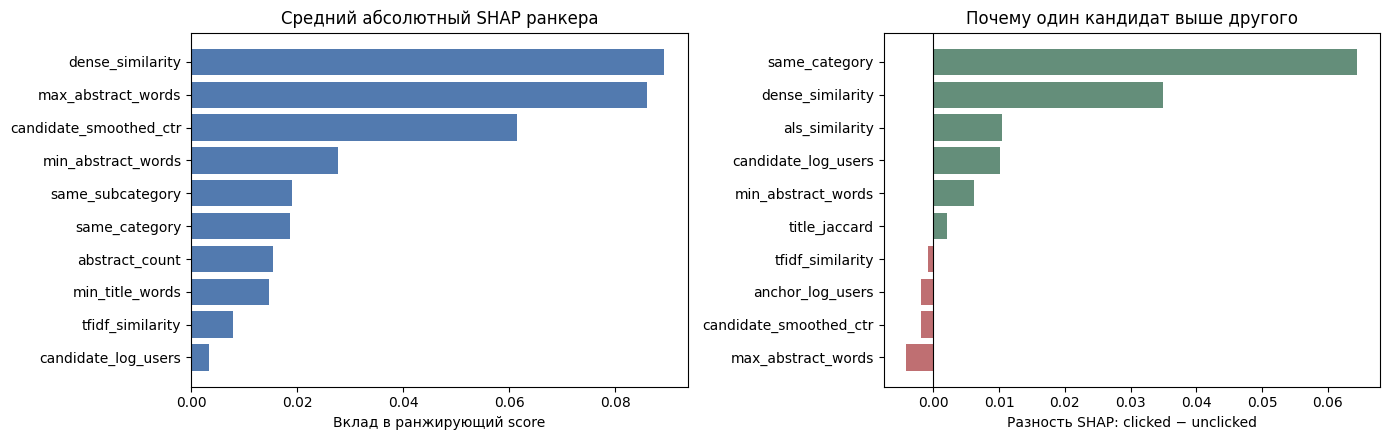

In [26]:
ranking_test = logged_groups.filter(pl.col('split') == 'test')
rank_shap_pairs = ranking_test.sample(n=min(256, ranking_test.height), seed=SEED)
rank_shap_features = rank_features.frame(rank_shap_pairs['anchor_index'], rank_shap_pairs['candidate_index'])
rank_shap = shap_contributions(attractiveness['model'], rank_shap_features)
np.testing.assert_allclose(rank_shap['base_value'] + rank_shap['values'].sum(axis=1), attractiveness['model'].predict(rank_shap_features.to_numpy()), atol=1e-08)
display(rank_shap['importance'].head(10))
group = ranking_test.filter(pl.col('group_id') == ranking_test['group_id'][0])
pair = pl.concat([group.filter(pl.col('target') == 1).head(1), group.filter(pl.col('target') == 0).head(1)])
pair_features = rank_features.frame(pair['anchor_index'], pair['candidate_index'])
pair_shap = shap_contributions(attractiveness['model'], pair_features)
pair_scores = attractiveness['model'].predict(pair_features.to_numpy())
shap_difference = pair_shap['values'][0] - pair_shap['values'][1]
np.testing.assert_allclose(shap_difference.sum(), pair_scores[0] - pair_scores[1], atol=1e-08)
local_rank = pl.DataFrame({'feature': pair_features.columns, 'clicked_value': pair_features.row(0), 'unclicked_value': pair_features.row(1), 'shap_difference': shap_difference}).with_columns(pl.col('shap_difference').abs().alias('magnitude')).sort('magnitude', descending=True)
print('Anchor:', resources.rows[pair['anchor_index'][0]]['title'])
for j, label in enumerate(['Кликнутый', 'Некликнутый']):
    print(f"{label}: {resources.rows[pair['candidate_index'][j]]['title']} · score {pair_scores[j]:.3f}")
display(local_rank.drop('magnitude').head(10))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
global_rank = rank_shap['importance'].head(10).sort('mean_abs_shap')
axes[0].barh(global_rank['feature'], global_rank['mean_abs_shap'], color='#527aaf')
axes[0].set(title='Средний абсолютный SHAP ранкера', xlabel='Вклад в ранжирующий score')
shown = local_rank.head(10).sort('shap_difference')
axes[1].barh(shown['feature'], shown['shap_difference'], color=['#648e7a' if x >= 0 else '#bf6f72' for x in shown['shap_difference']])
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set(title='Почему один кандидат выше другого', xlabel='Разность SHAP: clicked − unclicked')
fig.tight_layout()
plt.show()

## 10. Пересортировка прошедших relevance-порог списков

![Прошедшие фильтр пары получают attractiveness score и новый rank без изменения состава](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/18_rerank.png)

**Вход:** множество $F_\tau(A)$ и 22 признака на пару. **Выход:** упорядоченный список L(A):

$$
L(A)=\operatorname{argsort}_{i\in F_\tau(A)}\big(-s(A,i),\,ID(i)\big).
$$

Сортируем по убыванию attractiveness score; при равенстве — по возрастанию ID.
Для сравнения сохраняем позиции до и после пересортировки и обе оценки модели.
Главный инвариант:

$$
\operatorname{items}(L(A))=F_\tau(A),\qquad |L(A)|=|F_\tau(A)|.
$$

Состав 4633 пар сохраняется. Здесь нет нового порога и top-K среза; пустые списки остаются пустыми.
Разный порядок кандидатов не изменяет уже выполненное решение о релевантности.
Этот порядок предназначен для одного anchor; online-смешивание нескольких списков — отдельная задача.


In [27]:
ranked_lists = attractiveness['ranked']
assert ranked_lists.height == filtered.height
assert set(ranked_lists.select('anchor_index', 'candidate_index').iter_rows()) == set(filtered.select('anchor_index', 'candidate_index').iter_rows())
assert ranked_lists['relevance_score'].min() >= TAU
print(f"Пересортировано {ranked_lists.height:,} пар; изменили позицию: {ranked_lists.filter(pl.col('relevance_rank') != pl.col('attractiveness_rank')).height:,}")
if not ranked_lists.is_empty():
    anchor = ranked_lists.group_by('anchor_index').len().sort(['len', 'anchor_index'], descending=[True, False])['anchor_index'][0]
    shown = with_news_ids(ranked_lists.filter(pl.col('anchor_index') == anchor), resources.rows).join(catalog.select(pl.col('news_id').alias('candidate_id'), 'title'), on='candidate_id').select('title', 'relevance_score', 'attractiveness_score', 'relevance_rank', 'attractiveness_rank')
    print('Anchor:', resources.rows[anchor]['title'])
    print('До пересортировки:')
    display(shown.sort('relevance_rank').head(10))
    print('После пересортировки:')
    display(shown.sort('attractiveness_rank').head(10))

Пересортировано 4,688 пар; изменили позицию: 4,367
Anchor: World Series Game 2 Highlights: Nationals vs. Astros
До пересортировки:


title,relevance_score,attractiveness_score,relevance_rank,attractiveness_rank
str,f64,f64,i64,i64
"""World Series Game 2: Nationals dominate Astros to take 2-0 lead""",0.993476,0.391908,1,78
"""World Series Open Thread: Nationals vs. Astros""",0.989629,0.387269,2,80
"""MLB world reacts to Astros' seventh-inning collapse in Game 2 of…",0.989449,0.455614,3,19
"""Winners, losers from the Nationals' dominating Game 2 win""",0.988079,0.437631,4,35
"""Astros and Nationals head to winner-take-all World Series game""",0.985681,0.391119,5,79
"""Nationals Vs. Astros, World Series Game 2: What You Need To Know""",0.97857,0.437163,6,37
"""World Series: How the Nationals and Astros match up""",0.97816,0.437952,7,28
"""NLCS Game 4: Nationals complete sweep to clinch first-ever World…",0.97585,0.406383,8,70
"""Washington Nationals' lineup for Game 7 of the World Series with…",0.975222,0.426927,9,62


После пересортировки:


title,relevance_score,attractiveness_score,relevance_rank,attractiveness_rank
str,f64,f64,i64,i64
"""John Farrell Breaks Down the Nationals That Stepped Up in Game 7…",0.943196,0.726179,56,1
"""World Series Game 1 Highlights: Nationals vs. Astros""",0.864782,0.706668,107,2
"""How Is Houston and Washington Feeling Ahead of the World Series?""",0.844981,0.69378,114,3
"""Steve Phillips Previews Game 6 of the World Series""",0.891962,0.651561,93,4
"""World Series Game 4 Highlights: Astros vs. Nationals""",0.8026,0.595444,126,5
"""World Series Game 7 Highlights: Nationals vs. Astros""",0.91954,0.595444,78,6
"""World Series Game 6 Highlights: Nationals vs. Astros""",0.890299,0.593829,96,7
"""12 burning questions for Nationals-Astros World Series""",0.944874,0.539309,51,8
"""Nationals crush Astros for 2-0 World Series lead""",0.967575,0.512488,16,9


## 11. Сборка пользовательского пула из десяти списков

![Списки десяти anchors объединяются по ID; seen-фильтр удаляет всю известную историю](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/19_runtime.png)

**Вход:** выбранные $H_h(u)$ и сохранённые списки L(A).
**Выход:** уникальные пользовательские кандидаты и anchor-объяснения:

$$
C(u)=\left(\bigcup_{A\in H_h(u)}\operatorname{items}(L(A))\right)\setminus H(u),\qquad
Support(u,i)=\{A\in H_h(u):i\in\operatorname{items}(L(A))\}.
$$

Исключаем всю обучающую историю, а не только выбранные десять anchors.
Кандидат с несколькими источниками объяснения остаётся одним объектом;
Число поддерживающих anchors показывает, сколько интересов пользователя привели к кандидату.
Пересортировка сохранила состав L(A), поэтому она не меняет состав C(u).

В коде ниже пользовательский union читается из relevance-списков с тем же составом.
Для диагностики порядок задаёт:

$$
r_u(i)=\max_{A\in Support(u,i)}r(A,i).
$$

Основное объяснение — anchor с максимальной релевантностью; остальные объяснения тоже сохраняются.
Это не итоговая персональная формула аттрактивности: её здесь не обучаем.
PairLogit score между anchors не калиброван; онлайн-блендеру нужна отдельная политика смешивания.
После seen-фильтра все 50 пользователей имеют кандидатов, в среднем 94.44 на пользователя.


In [28]:
users = user_candidates(sample, scored, resources.user_item, threshold=TAU)
example = with_news_ids(users.filter(pl.col('user_id') == first_user).head(15), resources.rows).join(catalog.select(pl.col('news_id').alias('candidate_id'), pl.col('title').alias('candidate_title'), 'category'), on='candidate_id').join(catalog.select(pl.col('news_id').alias('best_anchor_id'), pl.col('title').alias('because_of')), on='best_anchor_id')
display(example.select('display_rank', 'candidate_title', 'category', 'relevance_score', 'support_count', 'because_of').sort('display_rank'))
user_sizes = sample.select('user_id').unique().join(users.group_by('user_id').len(), on='user_id', how='left').fill_null(0)
display(user_sizes.select(pl.col('len').min().alias('min_candidates'), pl.col('len').median().alias('median_candidates'), pl.col('len').max().alias('max_candidates')))

display_rank,candidate_title,category,relevance_score,support_count,because_of
i64,str,str,f64,i64,str
1,"""Missing New Hampshire couple's bodies found buried on a Texas be…","""news""",0.994461,1,"""New Hampshire Couple's Adventure Ends in Mysterious Death in Tex…"
2,"""Watch: Man is arrested after stabbing 'Baby Trump' balloon""","""news""",0.988608,1,"""'Baby Trump' balloon slashed at Alabama appearance"""
3,"""Texas police hunt for killer after finding New Hampshire couple …","""news""",0.986622,1,"""New Hampshire Couple's Adventure Ends in Mysterious Death in Tex…"
4,"""Pallbearer at Elijah Cummings' memorial claims he snubbed McConn…","""news""",0.984375,1,"""Mitch McConnell snubbed by Elijah Cummings' pallbearer in handsh…"
5,"""'Baby Trump' balloon slashed while in Tuscaloosa""","""video""",0.980897,1,"""'Baby Trump' balloon slashed at Alabama appearance"""
6,"""People raise thousands for man who allegedly stabbed 'Baby Trump…","""news""",0.978933,1,"""'Baby Trump' balloon slashed at Alabama appearance"""
…,…,…,…,…,…
10,"""Felicity Huffman released from federal prison early""","""tv""",0.972602,1,"""Felicity Huffman Smiles as She Begins Community Service Followin…"
11,"""A man went viral for snubbing Mitch McConnell at Elijah Cummings…","""news""",0.96713,1,"""Mitch McConnell snubbed by Elijah Cummings' pallbearer in handsh…"


min_candidates,median_candidates,max_candidates
u32,f64,u32
6,75.5,398


## 12. Насколько сократились списки?

![Размеры до и после измеряются на всех anchors, включая нулевые, с явными знаменателями](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/20_sizes.png)

**Вход:** union, scores и полный набор anchors $S$.
Для anchor A обозначим $n_0(A)=|C(A)|$, $n_\tau(A)=|F_\tau(A)|$.
Средняя длина включает пустые списки:

$$
\overline n_\tau=\frac1{|S|}\sum_{A\inS}n_\tau(A),\qquad
Coverage_{anchor}=\frac1{|S|}\sum_{A\inS}1[n_\tau(A)>0].
$$

Важно различать долю сокращения **по всем парам** и среднюю долю **по anchors**:

$$
Drop_{pairs}=1-\frac{\sum_A n_\tau(A)}{\sum_A n_0(A)},\qquad
MeanDrop_{anchor}=\frac1{|S_+|}\sum_{A\inS_+}
\left(1-\frac{n_\tau(A)}{n_0(A)}\right),\quad S_+=\{A:n_0(A)>0\}.
$$

Первая величина сильнее взвешивает длинные списки; во второй каждый anchor имеет одинаковый вес.
Таблица ниже показывает размеры, сохранённую долю **по парам**, непустые anchors и пользовательские пулы.
Средние проценты по всем этапам позже сведём в завершающую таблицу.

Покрытие выбранных позитивов после seen-фильтра — ещё одна отдельная величина:

$$
Coverage_{history}=\frac{\sum_u\sum_{A\in H_h(u)}
1[\operatorname{items}(L(A))\setminus H(u)\ne\varnothing]}
{\sum_u|H_h(u)|}.
$$

Это доля позиций истории с хотя бы одним непрочитанным кандидатом.
Она отличается от recall классификатора на размеченных парах и от покрытия уникальных anchors.
При τ=0.8 coverage_history=67.8%; coverage_anchor=316/461≈68.5%.


threshold,pairs_after,mean_anchor_length,anchor_coverage,mean_user_candidates,history_coverage_after_seen_filter
f64,i64,f64,f64,f64,f64
0.0,127221,275.967462,1.0,2519.58,1.0
0.2,21340,46.290672,0.965293,427.88,0.966
0.5,11066,24.004338,0.845987,226.26,0.844
0.7,6674,14.477223,0.776573,135.96,0.766
0.8,4688,10.169197,0.70282,95.72,0.694
0.9,2570,5.574837,0.559653,52.98,0.558
0.95,1255,2.722343,0.429501,26.04,0.432


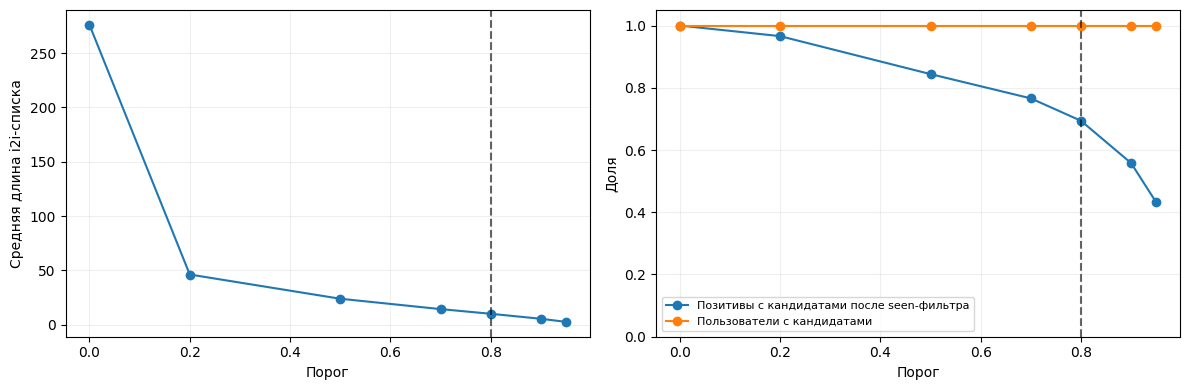

In [29]:
comparison = threshold_statistics(scored, sample, resources.user_item, [0, 0.2, TAU, 0.5, 0.7, 0.8, 0.9, 0.95])
display(comparison.select('threshold', 'pairs_after', 'mean_anchor_length', 'anchor_coverage', 'mean_user_candidates', 'history_coverage_after_seen_filter'))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(comparison['threshold'], comparison['mean_anchor_length'], marker='o')
axes[0].set(xlabel='Порог', ylabel='Средняя длина i2i-списка')
axes[1].plot(comparison['threshold'], comparison['history_coverage_after_seen_filter'], marker='o', label='Позитивы с кандидатами после seen-фильтра')
axes[1].plot(comparison['threshold'], comparison['nonempty_users'] / USER_COUNT, marker='o', label='Пользователи с кандидатами')
axes[1].set(xlabel='Порог', ylabel='Доля', ylim=(0, 1.05))
axes[1].legend(fontsize=8)
for ax in axes:
    ax.axvline(TAU, color='black', linestyle='--', alpha=0.6)
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(ARTIFACTS / 'threshold_effect.png', dpi=150)
plt.show()

## 13. Проверка согласованности конвейера

![Пары соседних этапов сравниваются по составу, порогам, истории и временным группам](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/21_artifacts.png)

Проследим связь результатов: каждый отфильтрованный кандидат присутствовал в union,
каждая пересортированная пара прошла relevance-порог, каждый пользовательский кандидат
пришёл хотя бы из одного выбранного anchor и отсутствует в прочитанном.

Согласованность проверяем не только числом строк:

$$
Pairs_{ranked}=Pairs_{filtered},\qquad
\min_{(A,i)\in Pairs_{filtered}}r(A,i)\ge0.8,\qquad
C(u)\cap H(u)=\varnothing.
$$

Дополнительно: нет самопар и дублей, по 10 различных anchors на пользователя,
группы одного показа не пересекают временные split, ранги последовательны,
аттрактивность внутри каждого списка невозрастает.
Эти проверки связывают этапы в один конвейер и помогают заметить ошибки объединения или перестановку ID.
Сводную таблицу средних процентов отсева по всем этапам соберём в завершение семинара.


In [30]:
assert sample.group_by('user_id').len()['len'].min() == HISTORY_SIZE
assert scored.select(pl.struct('anchor_index', 'candidate_index').n_unique()).item() == scored.height
assert logged_groups.group_by('impression_id').agg(pl.col('split').n_unique())['split'].max() == 1
assert ranked_lists.select(pl.struct('anchor_index', 'candidate_index').n_unique()).item() == filtered.height
display(pl.DataFrame([{'Пользователей': sample['user_id'].n_unique(), 'Позитивов на пользователя': HISTORY_SIZE, 'Уникальных anchors': len(anchor_indices), 'Рёбер источников': edges.height, 'Пар union': scored.height, 'Пар после фильтра': filtered.height}]))
print('Проверки согласованности пройдены.')

Пользователей,Позитивов на пользователя,Уникальных anchors,Рёбер источников,Пар union,Пар после фильтра
i64,i64,i64,i64,i64,i64
50,10,461,138300,127221,4688


Проверки согласованности пройдены.


## 14. Оценка пользы кандидатогенерации

![Сравнение на одной когорте будущих кликов, с ранними признаками и одинаковым бюджетом](https://raw.githubusercontent.com/girafe-ai/recsys/26f/seminars/10_i2i_lists/assets/diagrams/22_evaluation.png)

Проверим три отдельных эффекта: **добавление источников**, **relevance-фильтр** и **порядок по аттрактивности**.
Для каждого пользователя берём первый показ 14 ноября. Если до него есть хотя бы десять позитивов
и в самом показе есть новый клик, пользователь может попасть в выборку из 200 человек.
Десять anchors случайно выбираются только из предшествующей истории; target — новые clicked этого показа.
Когорту и anchors фиксируем для всех вариантов, включая пустые выдачи.

Оценку на полном train-снимке делать нельзя: его ALS и популярности уже содержат клики 14 ноября.
Здесь используем **ранний снимок до 10 ноября** и соответствующий ALS.
Модель релевантности заново обучаем на тех же LLM train-парах с ранними поведенческими признаками;
модель аттрактивности уже обучена на 10–12 ноября, validation для неё — 13 ноября.
Каталог текстов фиксирован: доступность новых публикаций во времени в эту оценку не входит.

Каждый источник выдаёт до 100 объектов на anchor. Для одинакового финального бюджета оставляем top-100 на пользователя.
В базовом union ранги источников объединяем Reciprocal Rank Fusion:

$$
RRF(A,i)=\sum_{m:i\in KNN_m(A)}\frac1{c+rank_m(A,i)}.
$$

Внутри каждого anchor получаем порядок по source-RRF либо по аттрактивности.
Списки anchors смешиваем одинаковым правилом:

$$
RRF(u,i)=\sum_{A\in H_h(u):i\in L(A)}\frac1{c+rank_{L(A)}(i)}.
$$

Затем исключаем всю известную историю и выбираем top-100.
Это фиксированная политика сравнения, а не обученный персональный блендер;
абсолютные PairLogit scores разных anchors не сравниваем.

Пусть $G(u)$ — известные будущие клики, $C_v(u)$ — полный пул варианта v,
$TopK_v(u)$ — его первые K объектов. Измеряем:

$$
Recall_{pool}=\frac1{|U|}\sum_u\frac{|G(u)\cap C_v(u)|}{|G(u)|},\qquad
Recall@K=\frac1{|U|}\sum_u\frac{|G(u)\cap TopK_v(u)|}{|G(u)|},
$$

$$
HitRate@K=\frac1{|U|}\sum_u1[G(u)\cap TopK_v(u)\ne\varnothing].
$$

NDCG@100 считаем относительно этих же наблюдавшихся кликов; определение DCG такое же, как в разделе аттрактивности.
Recall полного пула отвечает на вопрос «нашли ли нужный объект вообще?»;
Recall@100 и NDCG@100 проверяют, удалось ли поставить его в ограниченную выдачу.
Для разниц используем парный bootstrap по одним и тем же пользователям, 2000 повторов, 95% интервал.
Это оценка **наблюдавшихся кликов**, а не непредвзятая оценка CTR или precision для непоказанных объектов.


In [31]:
def train_relevance_snapshot(features, labels_path, output_dir, target_precision=0.9, seed=42, fixed_threshold=None, threshold_rule='f1', trainer=None):
    from catboost import CatBoostClassifier
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    labelled = pl.read_parquet(labels_path)
    if labelled.group_by('anchor_id').agg(pl.col('split').n_unique())['split'].max() != 1:
        raise ValueError('Anchor occurs in more than one labelled split')
    known = labelled.filter(pl.col('relevant').is_not_null())
    a = [features.index[x] for x in known['anchor_id']]
    b = [features.index[x] for x in known['candidate_id']]
    matrix = features.frame(a, b).to_numpy()
    labels = known['relevant'].cast(pl.UInt8).to_numpy()
    split = known['split'].to_numpy()
    train, validation, test = [np.flatnonzero(split == name) for name in ['train', 'validation', 'test']]
    params = dict(iterations=1200, depth=6, learning_rate=0.05, loss_function='Logloss', eval_metric='AUC', l2_leaf_reg=5, random_seed=seed, thread_count=4, allow_writing_files=False)
    settings = dict(label_file_sha256=file_hash(labels_path), resources=features.fingerprint, feature_version=FEATURE_VERSION, feature_names=FEATURE_NAMES, params=params, target_precision=target_precision)
    model_path, report_path = (output_dir / 'relevance_model.cbm', output_dir / 'classification_report.json')
    report = json.loads(report_path.read_text()) if report_path.exists() else None
    model = CatBoostClassifier(**params)
    if trainer is not None:
        model = trainer(params, matrix[train], labels[train], matrix[validation], labels[validation])
        model.save_model(str(model_path))
    elif model_path.exists() and report and (report.get('settings') == settings):
        model.load_model(str(model_path))
    else:
        model.fit(matrix[train], labels[train], eval_set=(matrix[validation], labels[validation]), early_stopping_rounds=80, verbose=False)
        model.save_model(str(model_path))
    scores = model.predict_proba(matrix)[:, 1]
    comparison_choice = choose_threshold(labels[validation], scores[validation], target_precision=target_precision, min_kept=50)
    choice = operating_threshold(labels[validation], scores[validation], fixed=fixed_threshold, target_precision=target_precision, min_kept=50, rule=threshold_rule)
    report = dict(settings=settings, ignored_unknown=labelled.height - known.height, tree_count=model.tree_count_, threshold=choice, validation_precision_threshold=comparison_choice, metrics={name: classification_metrics(labels[indices], scores[indices], choice['threshold']) for name, indices in [('train', train), ('validation', validation), ('test', test)]})
    known.with_columns(pl.Series('relevance_score', scores)).write_parquet(output_dir / 'labelled_predictions.parquet')
    threshold_curve(labels[validation], scores[validation]).write_parquet(output_dir / 'validation_thresholds.parquet')
    pl.DataFrame(dict(feature=FEATURE_NAMES, importance=model.get_feature_importance())).sort('importance', descending=True).write_csv(output_dir / 'feature_importance.csv')
    report_path.write_text(json.dumps(report, ensure_ascii=False, indent=2) + '\n')
    return (model, report)

COHORT_SCHEMA = dict(user_id=pl.String, impression_id=pl.String, timestamp=pl.String, anchors=pl.List(pl.Int64), seen=pl.List(pl.Int64), positives=pl.List(pl.Int64))

def evaluation_cohort(records, alias_index, count=200, history_size=10, seed=42):
    first = {}
    for record in sorted(records, key=lambda r: (r['timestamp'], r['impression_id'])):
        if '2019-11-14' <= record['timestamp'] < '2019-11-15':
            first.setdefault(record['user_id'], record)
    eligible = []
    for user in sorted(first):
        record = first[user]
        history = sorted({alias_index[x] for x in record['history'].split() if x in alias_index})
        positives = sorted((i for i, y in shown_items(record, alias_index).items() if y and i not in history))
        if len(history) >= history_size and positives:
            eligible.append((record, history, positives))
    rng = np.random.default_rng(seed)
    selected = sorted(rng.choice(len(eligible), min(count, len(eligible)), replace=False))
    rows = []
    for i in selected:
        record, history, positives = eligible[i]
        anchors = sorted(rng.choice(history, history_size, replace=False).tolist())
        rows.append(dict(user_id=record['user_id'], impression_id=record['impression_id'], timestamp=record['timestamp'], anchors=anchors, seen=history, positives=positives))
    return pl.DataFrame(rows, schema=COHORT_SCHEMA)

def fuse_user_lists(cohort, lists, score_column, rrf_constant=60):
    by_anchor = {}
    ordered = lists.sort(['anchor_index', score_column, 'candidate_index'], descending=[False, True, False])
    for (anchor,), group in ordered.group_by('anchor_index', maintain_order=True):
        by_anchor[anchor] = group['candidate_index'].to_list()
    pools = {}
    for row in cohort.iter_rows(named=True):
        scores = defaultdict(float)
        seen = set(row['seen'])
        for anchor in row['anchors']:
            for rank, candidate in enumerate(by_anchor.get(anchor, []), 1):
                if candidate not in seen:
                    scores[candidate] += 1 / (rrf_constant + rank)
        pools[row['user_id']] = sorted(scores, key=lambda item: (-scores[item], item))
    return pools

def user_metrics(cohort, pools, k=100):
    rows = []
    for row in cohort.iter_rows(named=True):
        target = set(row['positives'])
        if not target:
            raise ValueError('Evaluation users must have a held-out positive')
        pool = list(dict.fromkeys(pools.get(row['user_id'], [])))
        top = pool[:k]
        hits = np.array([candidate in target for candidate in top], dtype=float)
        dcg = float(np.sum(hits / np.log2(np.arange(len(top)) + 2)))
        ideal = float(np.sum(1 / np.log2(np.arange(min(k, len(target))) + 2)))
        rows.append(dict(user_id=row['user_id'], positives=len(target), candidates=len(pool), empty=not pool, recall_pool=len(target & set(pool)) / len(target), recall_at_k=len(target & set(top)) / len(target), hit_rate_at_k=float(bool(target & set(top))), ndcg_at_k=dcg / ideal))
    return pl.DataFrame(rows)

def paired_difference(variant, baseline, metric, seed=42, bootstrap_samples=2000):
    merged = variant.select('user_id', metric).join(baseline.select('user_id', pl.col(metric).alias('baseline')), on='user_id', how='inner').sort('user_id')
    if merged.height != variant.height or merged.height != baseline.height:
        raise ValueError('Paired comparison requires identical user cohorts')
    differences = (merged[metric] - merged['baseline']).to_numpy()
    rng = np.random.default_rng(seed)
    samples = differences[rng.integers(0, len(differences), size=(bootstrap_samples, len(differences)))].mean(axis=1)
    return dict(metric=metric, delta=float(differences.mean()), ci_low=float(np.quantile(samples, 0.025)), ci_high=float(np.quantile(samples, 0.975)))

def run_candidate_evaluation(data_dir, pipeline_dir, count=200, history_size=10, k=100, budget=100, seed=42):
    from catboost import CatBoostRanker
    data_dir, pipeline_dir = (Path(data_dir), Path(pipeline_dir))
    output = pipeline_dir / 'evaluation'
    output.mkdir(parents=True, exist_ok=True)
    resources = load_resources(data_dir, pipeline_dir)
    records = read_behaviors(data_dir / 'raw' / 'MINDsmall_train.zip')
    index = {row['news_id']: i for i, row in enumerate(resources.rows)}
    aliases = json.loads((data_dir / 'aliases.json').read_text())
    alias_index = {old: index[new] for old, new in aliases.items()}
    cohort = evaluation_cohort(records, alias_index, count, history_size, seed)
    if cohort.is_empty():
        raise ValueError('No eligible evaluation users')
    cohort.write_parquet(output / 'cohort.parquet')
    attr_features, snapshot = prepare_attractiveness_features(resources, records, alias_index, pipeline_dir / 'attractiveness', seed)
    rel_model, rel_report = train_relevance_snapshot(attr_features.base, data_dir / 'expanded' / 'i2i_labelled.parquet', output, seed=seed, fixed_threshold=0.8)
    attr_model = CatBoostRanker()
    attr_model.load_model(str(pipeline_dir / 'attractiveness' / 'attractiveness_model.cbm'))
    attr_info = json.loads((pipeline_dir / 'attractiveness' / 'ranking_report.json').read_text())
    if attr_info['settings']['cutoff'] != snapshot['settings']['cutoff']:
        raise ValueError('Ranking model uses a different snapshot')
    vectors, _ = prepare_vectors(resources, pipeline_dir, seed)
    early_vectors = dict(vectors, als=attr_features.base.item_factors)
    import faiss
    indices = {name: faiss.read_index(str(pipeline_dir / f'{name}.faiss')) for name in ['dense', 'lexical']}
    index_dir = output / 'indices'
    index_dir.mkdir(parents=True, exist_ok=True)
    early_indices, _ = prepare_indices({'als': early_vectors['als']}, index_dir)
    indices['als'] = early_indices['als']
    anchors = np.sort(cohort['anchors'].explode().unique().to_numpy())
    edges = retrieve_candidates(indices, early_vectors, anchors, k)
    edges.write_parquet(output / 'retrieval_edges.parquet')
    union = edges.with_columns((1 / (60 + pl.col('rank'))).alias('rrf')).group_by('anchor_index', 'candidate_index').agg(pl.col('rrf').sum().alias('source_rrf'), pl.col('source').unique().sort().alias('sources'))
    union = score_candidates(union.sort('anchor_index', 'candidate_index'), attr_features.base, rel_model)
    matrix = attr_features.frame(union['anchor_index'], union['candidate_index'])
    union = union.with_columns(pl.Series('attractiveness_score', attr_model.predict(matrix.to_numpy())))
    union.write_parquet(output / 'candidates_scored.parquet')
    filtered = union.filter(pl.col('relevance_score') >= 0.8)
    variants = {name: (edges.filter(pl.col('source') == name), 'index_score') for name in ['dense', 'lexical', 'als']}
    variants.update(union=(union, 'source_rrf'), union_filter=(filtered, 'source_rrf'), union_filter_attractiveness=(filtered, 'attractiveness_score'), union_attractiveness=(union, 'attractiveness_score'))
    per_user, aggregates = ({}, [])
    for name, (frame, column) in variants.items():
        pools = fuse_user_lists(cohort, frame, column)
        values = user_metrics(cohort, pools, budget)
        per_user[name] = values
        values.with_columns(pl.lit(name).alias('variant')).write_parquet(output / f'metrics_{name}.parquet')
        aggregates.append(dict(variant=name, users=values.height, mean_candidates=values['candidates'].mean(), empty_fraction=values['empty'].mean(), recall_pool=values['recall_pool'].mean(), recall_at_k=values['recall_at_k'].mean(), hit_rate_at_k=values['hit_rate_at_k'].mean(), ndcg_at_k=values['ndcg_at_k'].mean()))
    aggregate = pl.DataFrame(aggregates)
    comparisons = []
    for left, right in [('union', 'dense'), ('union_filter', 'union'), ('union_filter_attractiveness', 'union_filter'), ('union_attractiveness', 'union'), ('union_filter_attractiveness', 'dense')]:
        for metric in ['recall_pool', 'recall_at_k', 'ndcg_at_k']:
            comparisons.append(dict(variant=left, baseline=right, **paired_difference(per_user[left], per_user[right], metric, seed)))
    deltas = pl.DataFrame(comparisons)
    aggregate.write_csv(output / 'comparison.csv')
    deltas.write_csv(output / 'paired_differences.csv')
    report = dict(seed=seed, users=cohort.height, history_size=history_size, k_per_source=k, final_budget=budget, behavioural_cutoff=snapshot['settings']['cutoff'], test_day='2019-11-14', user_queries='first test impression per user with >=10 prior positives and unseen clicks', source_fusion='RRF60', history_fusion='RRF60', unique_anchors=len(anchors), source_edges=edges.height, union_pairs=union.height, filtered_pairs=filtered.height, relevance_tree_count=rel_report['tree_count'], relevance_test=rel_report['metrics']['test'], cohort_sha256=file_hash(output / 'cohort.parquet'), attractiveness_model_sha256=file_hash(pipeline_dir / 'attractiveness' / 'attractiveness_model.cbm'), note='Fixed text catalogue; observed future clicks only, not unbiased CTR, precision, or content-availability backtest.')
    (output / 'evaluation_report.json').write_text(json.dumps(report, ensure_ascii=False, indent=2) + '\n')
    return dict(comparison=aggregate, deltas=deltas, per_user=per_user, cohort=cohort, report=report)

Вариант,Средний пул,"Recall пула, %","Recall@100, %","HitRate@100, %",NDCG@100
str,f64,f64,f64,f64,f64
"""Dense""",945.3,15.16,3.49,6.0,0.00899
"""Lexical""",946.7,9.38,2.64,4.0,0.0051
"""ALS""",901.2,0.62,0.0,0.0,0.0
"""Три источника""",2534.3,19.05,1.41,3.5,0.00362
"""Три источника + relevance""",77.5,1.83,1.33,2.5,0.00377
"""+ relevance + аттрактивность""",77.5,1.83,1.33,2.5,0.0043
"""Три источника + аттрактивность""",2534.3,19.05,2.67,4.0,0.00681


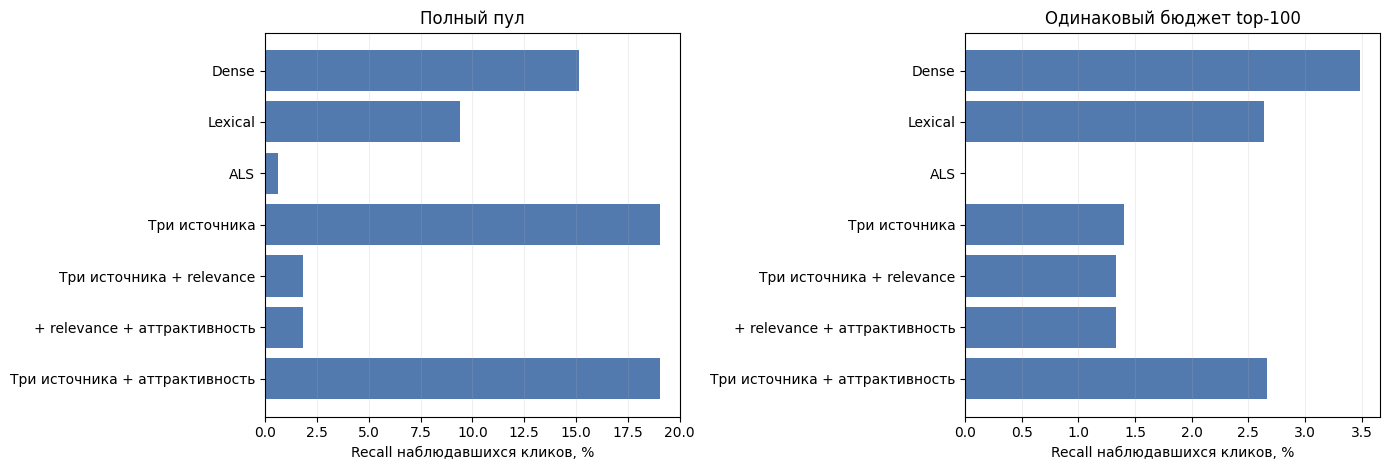

In [32]:
candidate_evaluation = run_candidate_evaluation(DATA, ARTIFACTS, count=200, history_size=10, k=100, budget=100, seed=SEED)
variant_names = {'dense': 'Dense', 'lexical': 'Lexical', 'als': 'ALS', 'union': 'Три источника', 'union_filter': 'Три источника + relevance', 'union_filter_attractiveness': '+ relevance + аттрактивность', 'union_attractiveness': 'Три источника + аттрактивность'}
comparison_eval = candidate_evaluation['comparison'].with_columns(pl.col('variant').replace_strict(variant_names).alias('Вариант'))
display(comparison_eval.select('Вариант', pl.col('mean_candidates').round(1).alias('Средний пул'), (100 * pl.col('recall_pool')).round(2).alias('Recall пула, %'), (100 * pl.col('recall_at_k')).round(2).alias('Recall@100, %'), (100 * pl.col('hit_rate_at_k')).round(2).alias('HitRate@100, %'), pl.col('ndcg_at_k').round(5).alias('NDCG@100')))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, metric, title in zip(axes, ['recall_pool', 'recall_at_k'], ['Полный пул', 'Одинаковый бюджет top-100']):
    ax.barh(comparison_eval['Вариант'], 100 * comparison_eval[metric], color='#527aaf')
    ax.invert_yaxis()
    ax.set(title=title, xlabel='Recall наблюдавшихся кликов, %')
    ax.grid(alpha=0.2, axis='x')
fig.tight_layout()
plt.show()

In [33]:
paired_eval = candidate_evaluation['deltas'].filter(pl.col('metric').is_in(['recall_pool', 'recall_at_k']))
display(paired_eval.select(pl.col('variant').replace_strict(variant_names).alias('Вариант'), pl.col('baseline').replace_strict(variant_names).alias('С чем сравниваем'), 'metric', (100 * pl.col('delta')).round(2).alias('Разница, п.п.'), (100 * pl.col('ci_low')).round(2).alias('95% CI снизу, п.п.'), (100 * pl.col('ci_high')).round(2).alias('95% CI сверху, п.п.')))
print('Пользователей в общей когорте:', candidate_evaluation['report']['users'])
print('Все варианты используют одинаковые anchors, будущие клики и бюджет100.')

Вариант,С чем сравниваем,metric,"Разница, п.п.","95% CI снизу, п.п.","95% CI сверху, п.п."
str,str,str,f64,f64,f64
"""Три источника""","""Dense""","""recall_pool""",3.89,1.54,6.63
"""Три источника""","""Dense""","""recall_at_k""",-2.08,-4.08,-0.42
"""Три источника + relevance""","""Три источника""","""recall_pool""",-17.22,-21.95,-12.61
"""Три источника + relevance""","""Три источника""","""recall_at_k""",-0.07,-1.74,1.61
"""+ relevance + аттрактивность""","""Три источника + relevance""","""recall_pool""",0.0,0.0,0.0
"""+ relevance + аттрактивность""","""Три источника + relevance""","""recall_at_k""",0.0,0.0,0.0
"""Три источника + аттрактивность""","""Три источника""","""recall_pool""",0.0,0.0,0.0
"""Три источника + аттрактивность""","""Три источника""","""recall_at_k""",1.26,-0.09,2.94
"""+ relevance + аттрактивность""","""Dense""","""recall_pool""",-13.33,-17.75,-9.39


Пользователей в общей когорте: 200
Все варианты используют одинаковые anchors, будущие клики и бюджет100.


**Что получилось на этом срезе**

- **Union повышает полноту полного пула:** recall растёт с 15.16% у dense до 19.05%. Разница +3.89 п.п., парный 95% bootstrap-интервал [+1.54; +6.63] п.п. При этом средний пул увеличивается с 945 до 2535 кандидатов.
- **Дополнительные источники ещё нужно правильно ранжировать:** при одинаковом top-100 recall у source-RRF union составляет 1.91% против 3.49% у dense. Рост полноты полного пула не гарантирует рост качества ограниченной выдачи.
- **Relevance-порог 0.8 имеет цену:** средний пул сокращается примерно до 78 объектов, recall полного пула — до 1.83%, Recall@100 — до 1.33%. Это компромисс с тематической связью относительно выбранных anchors: будущий клик может относиться к другому интересу пользователя.
- **Аттрактивность не меняет состав:** recall полного пула сохраняется. На отфильтрованном пуле NDCG@100 меняется с 0.00363 до 0.00383, но 95% интервал разницы включает 0. Уверенного вывода о выигрыше на этих 200 пользователях нет.
- **Для всей цепочки выигрыша по будущим кликам над dense на этом срезе нет.** Видны польза union для полноты и цена строгого фильтра. Уменьшение списка само по себе не доказывает рост CTR.

Оценка условна на фиксированном каталоге, выбранных anchors и наблюдавшихся показах. Ранний поведенческий снимок также устаревает к 14 ноября. Для вывода о пользе в сервисе понадобился бы отдельный онлайн-эксперимент.
